# Занятие 3. Разведочный анализ данных

Прогноз оттока «СвязьРегион». Ноутбук читает подготовленные таблицы второго этапа (`lesson2/output/`) и новые источники (`lesson3/data/`), строит исследовательскую таблицу снимков `eda_sample` и проверяет её.

**Запуск** из корня репозитория, одной командой:

```
jupyter nbconvert --to notebook --execute --inplace lesson3/eda.ipynb
```

Ядро работает в папке `lesson3/`, поэтому все пути ниже относительны неё. Результаты пишутся в `lesson3/output/`, словарь — в `lesson3/docs/`.

| Параметр | Правило |
|---|---|
| Единица наблюдения | пара `(customer_id, snapshot_at)` |
| Дата расчёта T | 00:00 по Москве первого числа месяца |
| Даты T для EDA | 01.12.2025 – 01.07.2026, 8 дат |
| Отложенные даты | валидация 01.08.2026, тест 01.09.2026 — в этом ноутбуке не строятся |
| Активная база | `activation < T` и (расторжения нет или `termination ≥ T`): состояние **до** событий на T |
| Горизонт | календарный месяц `[T, 1-е число следующего месяца)`, конец исключён |
| Метка | `termination` внутри горизонта; если конец горизонта позже 01.10.2026 — метка неизвестна, а не 0 |
| Признаки | строка `customer_month` за месяц T−1, доступная в `billing_available_at ≤ T` |

---

## Шаг 0. Конфигурация и загрузка

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

if not Path("eda.ipynb").exists():
    raise RuntimeError(f"Kernel must run in lesson3/, current folder is {Path.cwd()}")

# Inputs
LESSON2_OUTPUT = Path("../lesson2/output")  # prepared tables from lesson 2
LESSON1_RAW = Path("../lesson1/data/raw")   # raw event log, used only for an independent check
NEW_DATA = Path("data")                     # lesson 3 sources

# Outputs
OUTPUT = Path("output")
TABLES = OUTPUT / "tables"
FIGURES = OUTPUT / "figures"
DOCS = Path("docs")

MSK = "+03:00"
EDA_DATES = pd.date_range("2025-12-01", "2026-07-01", freq="MS")
VALIDATION_DATES = pd.DatetimeIndex(["2026-08-01"])
TEST_DATES = pd.DatetimeIndex(["2026-09-01"])
OUTCOMES_OBSERVED_BEFORE = pd.Timestamp("2026-10-01")  # the event log covers terminations before this date

CONFIG = {
    "unit_of_observation": "(customer_id, snapshot_at)",
    "snapshot_moment": "T 00:00 Moscow time (+03:00), first day of a month",
    "eda_dates": [f"{d:%Y-%m-%d}" for d in EDA_DATES],
    "validation_dates": [f"{d:%Y-%m-%d}" for d in VALIDATION_DATES],
    "test_dates": [f"{d:%Y-%m-%d}" for d in TEST_DATES],
    "active_base_rule": "activation < T and (no termination or termination >= T); state before the events dated T",
    "horizon": "calendar month [T, first day of next month), end excluded",
    "target": "termination inside the horizon; unknown (empty) when the horizon ends after outcomes_observed_before",
    "outcomes_observed_before": f"{OUTCOMES_OBSERVED_BEFORE:%Y-%m-%d}",
    "feature_source": "customer_month row for billing month T-1 with available_at <= T",
}
print(json.dumps(CONFIG, ensure_ascii=False, indent=2))

{
  "unit_of_observation": "(customer_id, snapshot_at)",
  "snapshot_moment": "T 00:00 Moscow time (+03:00), first day of a month",
  "eda_dates": [
    "2025-12-01",
    "2026-01-01",
    "2026-02-01",
    "2026-03-01",
    "2026-04-01",
    "2026-05-01",
    "2026-06-01",
    "2026-07-01"
  ],
  "validation_dates": [
    "2026-08-01"
  ],
  "test_dates": [
    "2026-09-01"
  ],
  "active_base_rule": "activation < T and (no termination or termination >= T); state before the events dated T",
  "horizon": "calendar month [T, first day of next month), end excluded",
  "target": "termination inside the horizon; unknown (empty) when the horizon ends after outcomes_observed_before",
  "outcomes_observed_before": "2026-10-01",
  "feature_source": "customer_month row for billing month T-1 with available_at <= T"
}


In [2]:
def read_csv(path: Path) -> pd.DataFrame:
    """Read a project CSV as text: UTF-8 with BOM, ';' separator, empty cell = missing."""
    if not path.exists():
        raise FileNotFoundError(f"Input not found: {path.resolve()}")
    return pd.read_csv(path, sep=";", encoding="utf-8-sig", dtype=str, keep_default_na=False)


def as_number(s: pd.Series) -> pd.Series:
    return pd.to_numeric(s.replace("", np.nan), errors="raise")


def as_int(s: pd.Series) -> pd.Series:
    values = as_number(s)
    if (values.dropna() % 1 != 0).any():
        raise ValueError(f"{s.name}: non-integer values")
    return values.astype("Int64")


def as_date(s: pd.Series) -> pd.Series:
    return pd.to_datetime(s.replace("", np.nan), format="%Y-%m-%d", errors="raise")


def as_moment(s: pd.Series) -> pd.Series:
    """ISO 8601 timestamps; every filled value must carry the Moscow offset."""
    filled = s[s != ""]
    foreign = filled[~filled.str.endswith(MSK)]
    if len(foreign):
        raise ValueError(f"{s.name}: {len(foreign)} values without {MSK}, e.g. {foreign.iloc[0]}")
    return pd.to_datetime(s.replace("", np.nan), format="ISO8601", errors="raise")


def as_bool(s: pd.Series) -> pd.Series:
    unexpected = set(s) - {"True", "False"}
    if unexpected:
        raise ValueError(f"{s.name}: unexpected values {sorted(unexpected)}")
    return s == "True"


def snapshot_moment(T: pd.Timestamp) -> pd.Timestamp:
    """Calculation moment of the calendar date T: 00:00 Moscow time."""
    return pd.Timestamp(f"{T:%Y-%m-%d}T00:00:00{MSK}")


def write_csv(df: pd.DataFrame, path: Path) -> None:
    """Project CSV format; dates as YYYY-MM-DD, moments as ISO 8601 with offset, '\n' line ends on every OS."""
    out = df.copy()
    for col in out.columns:
        s = out[col]
        if isinstance(s.dtype, pd.DatetimeTZDtype):
            out[col] = s.map(lambda v: v.isoformat() if pd.notna(v) else "")
        elif pd.api.types.is_datetime64_dtype(s):
            out[col] = s.dt.strftime("%Y-%m-%d")
    path.parent.mkdir(parents=True, exist_ok=True)
    out.to_csv(path, sep=";", encoding="utf-8-sig", index=False, lineterminator="\n")


def require(condition: bool, message: str) -> None:
    """Fail fast on a violated input precondition."""
    if not condition:
        raise ValueError(message)

In [3]:
subscribers = read_csv(LESSON2_OUTPUT / "subscribers_clean.csv")
events = read_csv(LESSON2_OUTPUT / "contract_events_clean.csv")
monthly = read_csv(LESSON2_OUTPUT / "customer_month.csv")
network = read_csv(NEW_DATA / "network_quality_monthly.csv")
context = read_csv(NEW_DATA / "business_context.csv")
raw_events = read_csv(LESSON1_RAW / "contract_events.csv")

subscribers["activation_date"] = as_date(subscribers.activation_date)
subscribers["activation_date_restored"] = as_bool(subscribers.activation_date_restored)

for table in (events, raw_events):
    table["event_date"] = as_date(table.event_date)

MONTHLY_FLOATS = ["monthly_fee_rub", "charged_rub", "paid_rub", "opening_debt_rub", "closing_debt_rub",
                  "traffic_gb", "support_score_mean"]
MONTHLY_INTS = ["voice_minutes", "active_days", "payment_delay_days", "tariff_changes_count",
                "support_count", "support_network_count", "support_billing_count", "support_unknown_topic_count",
                "support_flagged_count", "support_resolved_count", "support_score_count",
                "support_quarantined_linked_count"]
MONTHLY_BOOLS = ["closing_debt_restored", "traffic_gb_missing", "voice_minutes_invalid", "activation_date_restored"]

monthly["billing_month"] = as_date(monthly.billing_month)
monthly["activation_date"] = as_date(monthly.activation_date)
monthly["available_at"] = as_moment(monthly.available_at)
for col in MONTHLY_FLOATS:
    monthly[col] = as_number(monthly[col])
for col in MONTHLY_INTS:
    monthly[col] = as_int(monthly[col])
for col in MONTHLY_BOOLS:
    monthly[col] = as_bool(monthly[col])

network["measurement_month"] = as_date(network.measurement_month)
network["report_available_at"] = as_moment(network.report_available_at)
for col in ("probe_count", "failed_probe_count"):
    network[col] = as_int(network[col])
for col in ("download_mbps_p50", "download_mbps_p90"):
    network[col] = as_number(network[col])

context["event_start"] = as_date(context.event_start)
context["event_end"] = as_date(context.event_end)
context["announced_at"] = as_moment(context.announced_at)

pd.DataFrame({
    "table": ["subscribers_clean", "contract_events_clean", "customer_month", "network_quality_monthly",
              "business_context", "lesson1 contract_events (raw)"],
    "rows": [len(subscribers), len(events), len(monthly), len(network), len(context), len(raw_events)],
    "columns": [subscribers.shape[1], events.shape[1], monthly.shape[1], network.shape[1], context.shape[1],
                raw_events.shape[1]],
})

,table,rows,columns
0,subscribers_clean,2600,6
1,contract_events_clean,3299,4
2,customer_month,24098,31
3,network_quality_monthly,60,7
4,business_context,5,8
5,lesson1 contract_events (raw),3299,4


Проверки входа. Любое нарушение останавливает ноутбук: анализ на сломанном входе бессмыслен.

In [4]:
# Keys and references
require(subscribers.customer_id.is_unique, "subscribers_clean: duplicate customer_id")
require(events.event_id.is_unique, "contract_events_clean: duplicate event_id")
require(not monthly.duplicated(["customer_id", "billing_month"]).any(), "customer_month: duplicate key")
require(set(monthly.customer_id) <= set(subscribers.customer_id), "customer_month: unknown customer_id")
require(set(events.customer_id) == set(subscribers.customer_id), "events and subscribers cover different customers")
require(set(events.event_type) <= {"activation", "termination"}, "unexpected event_type")
require(not events.duplicated(["customer_id", "event_type"]).any(), "more than one event of a type per customer")

# Monthly table invariants used later
require((monthly.billing_month.dt.day == 1).all(), "billing_month is not a first day")
require((monthly.closing_debt_rub.dropna() >= 0).all(), "negative closing debt")
require((monthly.voice_minutes.dropna() >= 0).all(), "negative voice_minutes left after lesson 2")
require(monthly.traffic_gb.isna().equals(monthly.traffic_gb_missing), "traffic_gb_missing disagrees with traffic_gb")

# Network measurements
require(not network.duplicated(["region", "measurement_month"]).any(), "network: duplicate (region, month)")
require(set(network.region) == set(subscribers.region), "network regions differ from subscriber regions")
require((network.probe_count > 0).all(), "network: probe_count must be positive")
require(network.failed_probe_count.between(0, network.probe_count).all(), "network: failed outside [0, probe_count]")
require((network.download_mbps_p90 >= network.download_mbps_p50).all(), "network: p90 < p50")
month_end = (network.measurement_month + pd.DateOffset(months=1)).map(snapshot_moment)
require((network.report_available_at >= month_end).all(), "network: report published before the month ended")

# Context calendar
require(context.context_id.is_unique, "context: duplicate context_id")
require(set(context.event_type) <= {"support_migration", "seasonal_context", "measurement_alert"}, "context: event_type")
require(((context.scope == "region") == (context.region != "")).all(), "context: region must be set iff scope=region")
require((context.event_end >= context.event_start).all(), "context: event_end before event_start")

print("Input checks passed.")
print("Unknown traffic_gb in the whole customer_month:", int(monthly.traffic_gb.isna().sum()),
      "— an input check, not a statistic of the EDA base.")

Input checks passed.
Unknown traffic_gb in the whole customer_month: 240 — an input check, not a statistic of the EDA base.


*Шаг 0. Конфигурация и загрузка*

---

## Шаг 1. План исследования

Гипотезы и границы групп фиксируются **до** расчётов. Направление связи заранее не задаётся. Колонки `result`, `evidence`, `next_action` заполняются в конце ноутбука по рассчитанным числам.

In [5]:
TENURE_BINS = [0, 90, 365, np.inf]
DEBT_GROUPS = [">0", "=0", "неизвестен"]
SUPPORT_GROUPS = ["0", "1", "≥2", "неизвестно"]
TENURE_GROUPS = ["<90", "90–364", "≥365"]


def debt_group(debt: pd.Series) -> pd.Series:
    """Closing debt of month T-1: >0, =0, or unknown. Unknown is never merged into 'no debt'."""
    values = np.select([debt.isna(), debt > 0], ["неизвестен", ">0"], "=0")
    return pd.Series(pd.Categorical(values, categories=DEBT_GROUPS, ordered=True), index=debt.index)


def support_group(count: pd.Series) -> pd.Series:
    """Tickets created in month T-1 and known at T: 0, 1, >=2, or unknown."""
    values = np.select([count.isna(), count == 0, count == 1], ["неизвестно", "0", "1"], "≥2")
    return pd.Series(pd.Categorical(values, categories=SUPPORT_GROUPS, ordered=True), index=count.index)


def tenure_group(days: pd.Series) -> pd.Series:
    """Tenure at T in days, left-closed bins fixed before looking at churn."""
    return pd.cut(days, bins=TENURE_BINS, labels=TENURE_GROUPS, right=False, ordered=True)


EDA_PERIOD = "T = 01.12.2025–01.07.2026 (8 дат), горизонт — календарный месяц"
HYPOTHESES = pd.DataFrame([
    {"hypothesis_id": "H1",
     "question": "Отличается ли доля расторжений в следующем месяце у абонентов с долгом на конец прошлого месяца?",
     "indicator": "churn_rate = n_churn / n_observations; долг — closing_debt_rub в строке биллинга за T−1",
     "groups": "долг >0; =0; неизвестен",
     "limitations": "Повторные наблюдения одного абонента на разных T; долг может быть связан с тарифом и стажем; "
                    "часть значений долга восстановлена на этапе 2"},
    {"hypothesis_id": "H2",
     "question": "Связано ли число обращений в поддержку, известных к T, с уходом в следующем месяце?",
     "indicator": "churn_rate; support_count — обращения, созданные в месяце T−1 и доступные к T",
     "groups": "0; 1; ≥2 обращения",
     "limitations": "Учтён только прошлый месяц; обращения, ставшие известными после T, не учитываются; "
                    "обращение может быть следствием уже принятого решения уйти"},
    {"hypothesis_id": "H3",
     "question": "Меняются ли доля оттока и размер активной базы между датами T?",
     "indicator": "размер активной базы, n_churn, churn_rate на каждой T",
     "groups": "8 дат T",
     "limitations": "Восемь точек; синтетический набор; сезонные сообщения (B002, B005) — только пояснение, "
                    "не признак"},
    {"hypothesis_id": "H4",
     "question": "Отличается ли доля оттока у абонентов с разным стажем на T?",
     "indicator": "churn_rate; стаж = T − activation_date, дни",
     "groups": "<90; 90–364; ≥365 дней",
     "limitations": "Группа <90 дней малочисленна; новые абоненты могут отличаться тарифом и каналом; "
                    "абонент со временем переходит между группами"},
]).assign(period=EDA_PERIOD, expected_direction="не задаётся заранее", result="", evidence="", next_action="")

PLAN_COLUMNS = ["hypothesis_id", "question", "indicator", "groups", "period", "expected_direction",
                "limitations", "result", "evidence", "next_action"]
template_columns = list(read_csv(Path("analysis_plan.csv")).columns)
require(template_columns == PLAN_COLUMNS, f"analysis_plan.csv columns changed: {template_columns}")
HYPOTHESES = HYPOTHESES[PLAN_COLUMNS]
write_csv(HYPOTHESES, Path("analysis_plan.csv"))
HYPOTHESES[["hypothesis_id", "question", "groups"]]

,hypothesis_id,question,groups
0,H1,Отличается ли доля расторжений в следующем мес...,долг >0; =0; неизвестен
1,H2,"Связано ли число обращений в поддержку, извест...",0; 1; ≥2 обращения
2,H3,Меняются ли доля оттока и размер активной базы...,8 дат T
3,H4,Отличается ли доля оттока у абонентов с разным...,<90; 90–364; ≥365 дней


*Шаг 1. План исследования*

---

## Шаг 2. Исследовательская таблица снимков `eda_sample`

Три независимых шага на каждую дату T:

1. `active_base` — активная база только по журналу событий.
2. `snapshot_features` — показатели из строки биллинга за T−1. Строка обязана быть доступной к T: `billing_available_at ≤ snapshot_at`. Абонент без строки не удаляется, его показатели остаются пропусками.
3. `churn_target` — будущая метка. Дата расторжения используется только внутри этой функции и в таблицу не попадает.

`customer_month` содержит все месяцы биллинга, включая месяц расторжения. Строка за месяц T в снимок T не попадает: она станет известна только через месяц, а её `active_days` прямо выдаёт уходящих абонентов (устав, раздел 6).

Флаги качества сохраняются как служебные колонки. Их время доступности не подтверждено, поэтому признаками они не считаются.

In [6]:
STATIC_COLUMNS = ["region", "acquisition_channel", "customer_segment", "activation_date"]
BILLING_COLUMNS = ["tariff", "monthly_fee_rub", "charged_rub", "paid_rub", "opening_debt_rub", "closing_debt_rub",
                   "traffic_gb", "voice_minutes", "active_days", "payment_delay_days", "tariff_changes_count"]
SUPPORT_COLUMNS = ["support_count", "support_network_count", "support_billing_count", "support_unknown_topic_count",
                   "support_resolved_count", "support_score_count", "support_score_mean"]
QUALITY_COLUMNS = ["closing_debt_restored", "traffic_gb_missing", "voice_minutes_invalid", "activation_date_restored",
                   "support_flagged_count", "support_quarantined_linked_count"]
BILLING_QUALITY_COLUMNS = [c for c in QUALITY_COLUMNS if c != "activation_date_restored"]


def build_lifecycle(events: pd.DataFrame) -> pd.DataFrame:
    """One row per customer: activation date and optional termination date from the event log."""
    wide = events.pivot(index="customer_id", columns="event_type", values="event_date")  # raises on duplicates
    if "termination" not in wide:
        wide["termination"] = pd.NaT
    lifecycle = (wide.rename(columns={"activation": "activation_date", "termination": "termination_date"})
                 .rename_axis(columns=None).reset_index())
    require(lifecycle.activation_date.notna().all(), "customer without an activation event")
    require(not (lifecycle.termination_date < lifecycle.activation_date).any(), "termination before activation")
    return lifecycle[["customer_id", "activation_date", "termination_date"]]


def active_base(lifecycle: pd.DataFrame, T: pd.Timestamp) -> pd.DataFrame:
    """Active at T, state before the events dated T: activation < T and (no termination or termination >= T)."""
    term = lifecycle.termination_date
    active = (lifecycle.activation_date < T) & (term.isna() | (term >= T))
    return lifecycle.loc[active, ["customer_id"]].reset_index(drop=True)


def snapshot_features(base: pd.DataFrame, monthly: pd.DataFrame, subscribers: pd.DataFrame,
                      T: pd.Timestamp) -> pd.DataFrame:
    """Static fields plus the billing row of month T-1, which must be known at T."""
    snapshot_at = snapshot_moment(T)
    rows = monthly[monthly.billing_month == T - pd.DateOffset(months=1)]
    late = rows[rows.available_at > snapshot_at]
    require(late.empty, f"T={T:%Y-%m-%d}: {len(late)} billing rows of month T-1 are not yet available at T")
    billing = (rows[["customer_id", "billing_month", "available_at",
                     *BILLING_COLUMNS, *SUPPORT_COLUMNS, *BILLING_QUALITY_COLUMNS]]
               .rename(columns={"billing_month": "source_billing_month", "available_at": "billing_available_at"}))
    out = (base.assign(snapshot_at=snapshot_at)
           .merge(subscribers[["customer_id", *STATIC_COLUMNS, "activation_date_restored"]],
                  on="customer_id", how="left", validate="1:1")
           .merge(billing, on="customer_id", how="left", validate="1:1"))
    out["tenure_days"] = (T - out.activation_date).dt.days
    return out


def churn_target(base: pd.DataFrame, lifecycle: pd.DataFrame, T: pd.Timestamp) -> pd.DataFrame:
    """Future label for the base at T. The termination date never leaves this function."""
    end = T + pd.DateOffset(months=1)
    term = base.merge(lifecycle, on="customer_id", how="left", validate="1:1").termination_date
    if end > OUTCOMES_OBSERVED_BEFORE:
        target = pd.Series(pd.NA, index=base.index, dtype="Int64")  # outcome not fully observed: unknown, not 0
    else:
        target = ((term >= T) & (term < end)).astype("Int64")
    return pd.DataFrame({"customer_id": base.customer_id, "snapshot_at": snapshot_moment(T),
                         "target_end_exclusive": snapshot_moment(end), "churn_target": target})


SAMPLE_COLUMNS = ["customer_id", "snapshot_at", "source_billing_month", "billing_available_at",
                  *STATIC_COLUMNS, "tenure_days", *BILLING_COLUMNS, *SUPPORT_COLUMNS, *QUALITY_COLUMNS,
                  "target_end_exclusive", "churn_target"]


def build_snapshot(T: pd.Timestamp, lifecycle: pd.DataFrame) -> pd.DataFrame:
    base = active_base(lifecycle, T)
    features = snapshot_features(base, monthly, subscribers, T)
    target = churn_target(base, lifecycle, T)
    snapshot = features.merge(target, on=["customer_id", "snapshot_at"], how="inner", validate="1:1")
    require(len(snapshot) == len(base), f"T={T:%Y-%m-%d}: snapshot lost rows of the active base")
    return snapshot[SAMPLE_COLUMNS]


lifecycle = build_lifecycle(events)
eda_sample = pd.concat([build_snapshot(T, lifecycle) for T in EDA_DATES], ignore_index=True)

by_T = eda_sample.groupby("snapshot_at").agg(
    active_base=("customer_id", "size"),
    churn=("churn_target", "sum"),
    unknown_target=("churn_target", lambda s: int(s.isna().sum())),
    without_billing_row=("source_billing_month", lambda s: int(s.isna().sum())),
    tenure_under_90=("tenure_days", lambda s: int((s < 90).sum())),
)
print(f"eda_sample: {len(eda_sample)} rows, {eda_sample.customer_id.nunique()} customers, "
      f"{eda_sample.churn_target.notna().sum()} observed outcomes")
by_T

eda_sample: 15696 rows, 2319 customers, 15696 observed outcomes


,active_base,churn,unknown_target,without_billing_row,tenure_under_90
snapshot_at,,,,,
2025-12-01 00:00:00+03:00,1969,48,0,0,95
2026-01-01 00:00:00+03:00,1971,50,0,0,137
2026-02-01 00:00:00+03:00,1971,52,0,0,142
2026-03-01 00:00:00+03:00,1969,54,0,0,148
2026-04-01 00:00:00+03:00,1965,56,0,0,147
2026-05-01 00:00:00+03:00,1959,58,0,0,144
2026-06-01 00:00:00+03:00,1951,60,0,0,143
2026-07-01 00:00:00+03:00,1941,62,0,0,141


### Проверки снимков

Каждая проверка записывается в `CHECKS` и при нарушении останавливает ноутбук. Активная база пересчитывается вторым, независимым путём: по `activation_date` из справочника и расторжениям из **сырого** журнала первого этапа, на множествах Python без pandas-фильтров. Дополнительно числа сверяются с таблицей снимков из устава.

In [7]:
CHECKS = []


def record_check(check: str, passed: bool, detail: str) -> None:
    CHECKS.append({"check": check, "passed": bool(passed), "detail": detail})
    if not passed:
        raise AssertionError(f"{check}: {detail}")


# 1. Key uniqueness
dups = int(eda_sample.duplicated(["customer_id", "snapshot_at"]).sum())
record_check("key (customer_id, snapshot_at) is unique", dups == 0, f"duplicates: {dups}")

# 2. Independent active base and churn from subscribers + raw event log
activation = {r.customer_id: r.activation_date.date() for r in subscribers.itertuples()}
raw_terminations = raw_events[raw_events.event_type == "termination"]
require(raw_terminations.customer_id.is_unique, "raw log: several terminations for one customer")
termination = {r.customer_id: r.event_date.date() for r in raw_terminations.itertuples()}

independent = []
for T in EDA_DATES:
    t, end = T.date(), (T + pd.DateOffset(months=1)).date()
    expected = {c for c, a in activation.items() if a < t and (c not in termination or termination[c] >= t)}
    expected_churn = {c for c in expected if c in termination and t <= termination[c] < end}
    rows = eda_sample[eda_sample.snapshot_at == snapshot_moment(T)]
    independent.append({
        "snapshot_at": snapshot_moment(T),
        "base_sample": len(rows), "base_independent": len(expected),
        "same_customers": set(rows.customer_id) == expected,
        "churn_sample": int(rows.churn_target.sum()), "churn_independent": len(expected_churn),
        "same_churners": set(rows.loc[rows.churn_target == 1, "customer_id"]) == expected_churn,
    })
independent = pd.DataFrame(independent)
write_csv(independent, TABLES / "check_active_base_independent.csv")
record_check("active base matches an independent recount from raw events",
             bool(independent.same_customers.all() and independent.same_churners.all()),
             f"{len(independent)} dates; rows {independent.base_sample.sum()} vs {independent.base_independent.sum()}; "
             f"churn {independent.churn_sample.sum()} vs {independent.churn_independent.sum()}")

# 3. Charter table (lesson1/docs/project_charter.md, section 5)
CHARTER = {"2025-12-01": (1969, 48), "2026-01-01": (1971, 50), "2026-02-01": (1971, 52), "2026-03-01": (1969, 54),
           "2026-04-01": (1965, 56), "2026-05-01": (1959, 58), "2026-06-01": (1951, 60), "2026-07-01": (1941, 62)}
charter_ok = all((by_T.loc[snapshot_moment(pd.Timestamp(d)), "active_base"],
                  by_T.loc[snapshot_moment(pd.Timestamp(d)), "churn"]) == v for d, v in CHARTER.items())
record_check("base size and churn per T match the project charter", charter_ok,
             f"total {len(eda_sample)} rows / {int(eda_sample.churn_target.sum())} churn; charter 15696 / 440")

# 4. Activation date from events equals the reference book
same_activation = (lifecycle.merge(subscribers, on="customer_id", suffixes=("_events", "_book"))
                   .pipe(lambda d: (d.activation_date_events == d.activation_date_book).all()))
record_check("activation date in events equals subscribers_clean", same_activation, "all customers")

# 5. Feature availability
with_row = eda_sample.dropna(subset=["source_billing_month"])
available = (with_row.billing_available_at <= with_row.snapshot_at).all()
previous_month = (with_row.source_billing_month + pd.DateOffset(months=1)
                  == with_row.snapshot_at.dt.tz_localize(None)).all()
record_check("billing_available_at <= snapshot_at and source month is T-1", bool(available and previous_month),
             f"{len(with_row)} rows with a billing row")
missing_rows = int(eda_sample.source_billing_month.isna().sum())
record_check("every active customer has a billing row for T-1", missing_rows == 0,
             f"rows without T-1 billing (kept, not dropped): {missing_rows}")

# 6. No future information among the columns
leaking = [c for c in eda_sample.columns if "termination" in c]
record_check("termination date is not a column of eda_sample", not leaking, f"columns: {leaking or 'none'}")

pd.DataFrame(CHECKS)

,check,passed,detail
0,"key (customer_id, snapshot_at) is unique",True,duplicates: 0
1,active base matches an independent recount fro...,True,8 dates; rows 15696 vs 15696; churn 440 vs 440
2,base size and churn per T match the project ch...,True,total 15696 rows / 440 churn; charter 15696 / 440
3,activation date in events equals subscribers_c...,True,all customers
4,billing_available_at <= snapshot_at and source...,True,15696 rows with a billing row
5,every active customer has a billing row for T-1,True,"rows without T-1 billing (kept, not dropped): 0"
6,termination date is not a column of eda_sample,True,columns: none


### Граничные события на искусственном примере

В данных нет ни одного расторжения первого числа, поэтому граничные правила проверяются на выдуманных абонентах. Те же функции `active_base` и `churn_target`, что строят `eda_sample`.

In [8]:
T = pd.Timestamp("2026-03-01")       # horizon [2026-03-01, 2026-04-01)
T_LATE = pd.Timestamp("2026-10-01")  # horizon ends 2026-11-01, after the observed outcomes
d = pd.Timestamp
boundary = pd.DataFrame([
    # customer_id, activation, termination, expected in base at T, expected label at T
    ("X_activation_on_T",          d("2026-03-01"), pd.NaT,           False, None),
    ("X_activation_day_before_T",  d("2026-02-28"), pd.NaT,           True,  0),
    ("X_termination_on_T",         d("2020-01-01"), d("2026-03-01"),  True,  1),
    ("X_termination_day_before_T", d("2020-01-01"), d("2026-02-28"),  False, None),
    ("X_termination_last_day",     d("2020-01-01"), d("2026-03-31"),  True,  1),
    ("X_termination_on_end",       d("2020-01-01"), d("2026-04-01"),  True,  0),
], columns=["customer_id", "activation_date", "termination_date", "expected_in_base", "expected_target"])

base = active_base(boundary, T)
target = churn_target(base, boundary, T).set_index("customer_id").churn_target
boundary["in_base"] = boundary.customer_id.isin(base.customer_id)
boundary["churn_target"] = boundary.customer_id.map(target)
rule_ok = (boundary.in_base.equals(boundary.expected_in_base)
           and all(boundary.churn_target[boundary.in_base] == boundary.expected_target[boundary.in_base]))

late_base = active_base(boundary, T_LATE)
late_target = churn_target(late_base, boundary, T_LATE)
late_ok = len(late_base) > 0 and late_target.churn_target.isna().all()

record_check("boundary events on T and on the horizon end follow the rule", rule_ok,
             "activation on T excluded; termination on T = churn; termination on end_exclusive = not churn")
record_check("horizon ending after 2026-10-01 gives an unknown label, not 0", late_ok,
             f"T={T_LATE:%Y-%m-%d}: {len(late_target)} rows, all labels empty")
boundary

,customer_id,activation_date,termination_date,expected_in_base,expected_target,in_base,churn_target
0,X_activation_on_T,2026-03-01,NaT,False,NaN,False,<NA>
1,X_activation_day_before_T,2026-02-28,NaT,True,0.0,True,0
2,X_termination_on_T,2020-01-01,2026-03-01,True,1.0,True,1
3,X_termination_day_before_T,2020-01-01,2026-02-28,False,NaN,False,<NA>
4,X_termination_last_day,2020-01-01,2026-03-31,True,1.0,True,1
5,X_termination_on_end,2020-01-01,2026-04-01,True,0.0,True,0


### Словарь и запись результатов

In [9]:
FIELD_INFO = {
    # field: (role, source, description, unit)
    "customer_id": ("ключ", "subscribers_clean", "Идентификатор абонента; не признак", "—"),
    "snapshot_at": ("ключ", "конфигурация", "Момент расчёта T: 00:00 МСК первого числа", "дата и время"),
    "source_billing_month": ("служебное", "customer_month", "Месяц биллинга, из которого взяты показатели (T−1)", "месяц"),
    "billing_available_at": ("служебное", "customer_month.available_at", "Момент доступности строки биллинга; ≤ snapshot_at", "дата и время"),
    "region": ("признак", "subscribers_clean", "Регион обслуживания, постоянный", "—"),
    "acquisition_channel": ("признак", "subscribers_clean", "Канал подключения, постоянный", "—"),
    "customer_segment": ("признак", "subscribers_clean", "Сегмент абонента, постоянный", "—"),
    "activation_date": ("служебное", "subscribers_clean", "Дата подключения; используется для стажа", "дата"),
    "tenure_days": ("признак", "расчёт", "Стаж на T: snapshot_at − activation_date", "дни"),
    "tariff": ("признак", "customer_month", "Тариф в месяце T−1", "—"),
    "monthly_fee_rub": ("признак", "customer_month", "Абонентская плата тарифа в месяце T−1", "руб."),
    "charged_rub": ("признак", "customer_month", "Начислено за месяц T−1", "руб."),
    "paid_rub": ("признак", "customer_month", "Оплачено в месяце T−1", "руб."),
    "opening_debt_rub": ("признак", "customer_month", "Долг на начало месяца T−1", "руб."),
    "closing_debt_rub": ("признак", "customer_month", "Долг на конец месяца T−1; 0 — долга нет", "руб."),
    "traffic_gb": ("признак", "customer_month", "Трафик за месяц T−1; пусто — неизвестно, не 0", "ГБ"),
    "voice_minutes": ("признак", "customer_month", "Минуты за месяц T−1; пусто — неизвестно или было некорректно", "мин"),
    "active_days": ("признак", "customer_month", "Активные дни в месяце T−1", "дни"),
    "payment_delay_days": ("признак", "customer_month", "Дни просрочки оплаты в месяце T−1", "дни"),
    "tariff_changes_count": ("признак", "customer_month", "Смены тарифа в месяце T−1", "раз"),
    "support_count": ("признак", "customer_month", "Обращения, созданные в месяце T−1 и известные к T", "обращения"),
    "support_network_count": ("признак", "customer_month", "Из них по теме network", "обращения"),
    "support_billing_count": ("признак", "customer_month", "Из них по теме billing", "обращения"),
    "support_unknown_topic_count": ("признак", "customer_month", "Из них с неизвестной темой", "обращения"),
    "support_resolved_count": ("признак", "customer_month", "Из них закрытые, закрытие известно к T", "обращения"),
    "support_score_count": ("признак", "customer_month", "Число оценок, известных к T", "оценки"),
    "support_score_mean": ("признак", "customer_month", "Средняя оценка; пусто — оценок не было", "балл 1–5"),
    "closing_debt_restored": ("качество", "customer_month", "Долг восстановлен на этапе 2; не признак", "—"),
    "traffic_gb_missing": ("качество", "customer_month", "Трафик неизвестен; не признак", "—"),
    "voice_minutes_invalid": ("качество", "customer_month", "Минуты были отрицательными и переведены в пропуск; не признак", "—"),
    "activation_date_restored": ("качество", "subscribers_clean", "Дата подключения восстановлена по журналу; не признак", "—"),
    "support_flagged_count": ("качество", "customer_month", "Обращения с некорректным закрытием или оценкой; не признак", "обращения"),
    "support_quarantined_linked_count": ("качество", "customer_month", "Обращения из карантина этапа 2; не признак", "обращения"),
    "target_end_exclusive": ("метка", "конфигурация", "Конец горизонта, не включён: 1-е число следующего месяца", "дата и время"),
    "churn_target": ("метка", "contract_events_clean", "1 — termination в [snapshot_at, target_end_exclusive); пусто — исход не наблюдаем", "0/1"),
}
require(list(FIELD_INFO) == list(eda_sample.columns), "dictionary fields differ from eda_sample columns")
dictionary = pd.DataFrame([(f, *info) for f, info in FIELD_INFO.items()],
                          columns=["field", "role", "source", "description", "unit"])
dictionary.insert(2, "data_type", [str(eda_sample[f].dtype) for f in dictionary.field])
dictionary["missing_rows"] = [int(eda_sample[f].isna().sum()) for f in dictionary.field]

write_csv(eda_sample, OUTPUT / "eda_sample.csv")
write_csv(dictionary, DOCS / "eda_sample_dictionary.csv")
(OUTPUT / "config.json").write_text(json.dumps(CONFIG, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print(f"Written: {OUTPUT / 'eda_sample.csv'} ({len(eda_sample)} rows), dictionary, config")
dictionary

Written: output/eda_sample.csv (15696 rows), dictionary, config


,field,role,data_type,source,description,unit,missing_rows
0,customer_id,ключ,object,subscribers_clean,Идентификатор абонента; не признак,—,0
1,snapshot_at,ключ,"datetime64[s, UTC+03:00]",конфигурация,Момент расчёта T: 00:00 МСК первого числа,дата и время,0
2,source_billing_month,служебное,datetime64[ns],customer_month,"Месяц биллинга, из которого взяты показатели (...",месяц,0
3,billing_available_at,служебное,"datetime64[ns, UTC+03:00]",customer_month.available_at,Момент доступности строки биллинга; ≤ snapshot_at,дата и время,0
4,region,признак,object,subscribers_clean,"Регион обслуживания, постоянный",—,0
5,acquisition_channel,признак,object,subscribers_clean,"Канал подключения, постоянный",—,0
6,customer_segment,признак,object,subscribers_clean,"Сегмент абонента, постоянный",—,0
7,activation_date,служебное,datetime64[ns],subscribers_clean,Дата подключения; используется для стажа,дата,0
8,tenure_days,признак,int64,расчёт,Стаж на T: snapshot_at − activation_date,дни,0
9,tariff,признак,object,customer_month,Тариф в месяце T−1,—,0


*Шаг 2. Исследовательская таблица снимков `eda_sample`*

---

## Шаг 3. Описание данных

Всё описание — на строках «абонент × T» основного периода EDA с наблюдаемой меткой. Строки с неизвестной меткой исключаются из сравнений с оттоком; их число печатается. Абонентов с короткой историей и с пропусками отдельных показателей не удаляем: для каждой статистики указано, сколько известных значений в неё вошло.

Один абонент встречается на нескольких датах T, поэтому число строк больше числа людей.

In [10]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Reference palette (dataviz skill, light mode): surface, ink and the first categorical slots
COLORS = {"surface": "#fcfcfb", "text": "#0b0b0b", "muted": "#52514e", "grid": "#e4e3df",
          "s1": "#2a78d6", "s2": "#eb6834", "s3": "#1baf7a"}
plt.rcParams.update({
    "figure.facecolor": COLORS["surface"], "axes.facecolor": COLORS["surface"],
    "savefig.facecolor": COLORS["surface"], "font.family": "DejaVu Sans", "font.size": 9.5, "axes.titlesize": 10.5,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": COLORS["muted"], "axes.labelcolor": COLORS["text"], "text.color": COLORS["text"],
    "xtick.color": COLORS["muted"], "ytick.color": COLORS["muted"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COLORS["grid"], "grid.linewidth": 0.8, "axes.axisbelow": True,
})


def fmt_int(n) -> str:
    return f"{int(n):,}".replace(",", " ")


def fmt_num(x, digits: int = 1) -> str:
    return f"{x:,.{digits}f}".replace(",", " ").replace(".", ",")


def fmt_pct(x, digits: int = 1) -> str:
    return f"{x * 100:.{digits}f}".replace(".", ",") + "%"


def save_figure(fig, name: str) -> None:
    """PNG without software/date metadata, so a rerun produces the same file."""
    FIGURES.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight", metadata={"Software": None})
    plt.show()


eda = eda_sample[eda_sample.churn_target.notna()].copy()
n_unknown_target = len(eda_sample) - len(eda)
eda["debt_group"] = debt_group(eda.closing_debt_rub)
eda["support_group"] = support_group(eda.support_count)
eda["tenure_group"] = tenure_group(eda.tenure_days)

dates_per_customer = eda.groupby("customer_id").size()
overview = pd.DataFrame.from_records([
    ("Строк «абонент × T»", len(eda)),
    ("Уникальных абонентов", eda.customer_id.nunique()),
    ("Дат T", eda.snapshot_at.nunique()),
    ("Исключено строк с неизвестной меткой", n_unknown_target),
    ("Наблюдаемых исходов (метка 0 или 1)", len(eda)),
    ("Расторжений в горизонте", int(eda.churn_target.sum())),
    ("Абонентов на всех датах T", int((dates_per_customer == len(EDA_DATES)).sum())),
    ("Абонентов не на всех датах T", int((dates_per_customer < len(EDA_DATES)).sum())),
    ("Строк на абонента, в среднем", fmt_num(dates_per_customer.mean(), 2)),
], columns=["metric", "value"]).astype({"value": str})
write_csv(overview, TABLES / "base_overview.csv")
overview

,metric,value
0,Строк «абонент × T»,15696
1,Уникальных абонентов,2319
2,Дат T,8
3,Исключено строк с неизвестной меткой,0
4,Наблюдаемых исходов (метка 0 или 1),15696
5,Расторжений в горизонте,440
6,Абонентов на всех датах T,1627
7,Абонентов не на всех датах T,692
8,"Строк на абонента, в среднем","6,77"


### Пропуски (рисунок 1)

Пропуск бывает трёх видов, и смысл у них разный:

- **неизвестно** — значение должно было быть, но в источнике его нет или оно некорректно;
- **неприменимо** — значения не существует: например, нет средней оценки, если оценок не было;
- **не опубликовано к T** — значение появилось позже даты расчёта и на T неизвестно.

Сетевой показатель в `eda_sample` не входит (шаг 5). На рисунке он показан по строкам снимков: известен ли на T отчёт региона абонента за месяц T−1. Функция `network_availability` будет использована и на шаге 5.

In [11]:
def network_availability(network: pd.DataFrame, dates: pd.DatetimeIndex) -> pd.DataFrame:
    """One row per (region, measurement_month, snapshot_at): the report for month T-1 and whether it is known at T."""
    parts = [network[network.measurement_month == T - pd.DateOffset(months=1)].assign(snapshot_at=snapshot_moment(T))
             for T in dates]
    out = pd.concat(parts, ignore_index=True)
    out["report_known_at_T"] = out.report_available_at <= out.snapshot_at
    return out


availability = network_availability(network, EDA_DATES)
require(len(availability) == len(EDA_DATES) * network.region.nunique(), "network: a region-month is missing")
row_network = eda[["region", "snapshot_at"]].merge(
    availability[["region", "snapshot_at", "report_known_at_T"]], on=["region", "snapshot_at"], how="left",
    validate="m:1")
require(len(row_network) == len(eda), "network availability changed the number of rows")

MISSING_INDICATORS = [
    # column, label, category, reason
    ("traffic_gb", "Трафик за T−1", "неизвестно", "Пропуск в источнике биллинга (учебный дефект); это не ноль"),
    ("voice_minutes", "Минуты за T−1", "неизвестно", "Отрицательное значение в источнике переведено в пропуск"),
    ("support_score_mean", "Средняя оценка обращений", "неприменимо",
     "В месяце T−1 нет оценённых обращений, известных к T"),
    ("network_report", "Сеть: доля неуспешных проб за T−1", "не опубликовано к T",
     "Отчёт за месяц T−1 опубликован после 00:00 первого числа"),
    ("closing_debt_rub", "Долг на конец T−1", "—", ""),
    ("support_count", "Обращения за T−1", "—", ""),
    ("payment_delay_days", "Задержка оплаты за T−1", "—", ""),
    ("tariff", "Тариф за T−1", "—", ""),
    ("tenure_days", "Стаж на T", "—", ""),
    ("region", "Регион", "—", ""),
]
missing = []
for col, label, category, reason in MISSING_INDICATORS:
    is_missing = ~row_network.report_known_at_T if col == "network_report" else eda[col].isna()
    n_missing = int(is_missing.sum())
    missing.append({"indicator": col, "label": label, "n_rows": len(eda), "n_missing": n_missing,
                    "n_known": len(eda) - n_missing, "missing_share": round(n_missing / len(eda), 6),
                    "category": category if n_missing else "—", "reason": reason if n_missing else ""})
missing = pd.DataFrame(missing).sort_values(["missing_share", "label"], ascending=[True, False]).reset_index(drop=True)
write_csv(missing, TABLES / "fig1_missing.csv")
missing

,indicator,label,n_rows,n_missing,n_known,missing_share,category,reason
0,tariff,Тариф за T−1,15696,0,15696,0.000000,—,
1,tenure_days,Стаж на T,15696,0,15696,0.000000,—,
2,region,Регион,15696,0,15696,0.000000,—,
3,support_count,Обращения за T−1,15696,0,15696,0.000000,—,
4,payment_delay_days,Задержка оплаты за T−1,15696,0,15696,0.000000,—,
5,closing_debt_rub,Долг на конец T−1,15696,0,15696,0.000000,—,
6,voice_minutes,Минуты за T−1,15696,50,15646,0.003186,неизвестно,Отрицательное значение в источнике переведено ...
7,traffic_gb,Трафик за T−1,15696,147,15549,0.009365,неизвестно,Пропуск в источнике биллинга (учебный дефект);...
8,network_report,Сеть: доля неуспешных проб за T−1,15696,9387,6309,0.598050,не опубликовано к T,Отчёт за месяц T−1 опубликован после 00:00 пер...
9,support_score_mean,Средняя оценка обращений,15696,12449,3247,0.793132,неприменимо,"В месяце T−1 нет оценённых обращений, известны..."


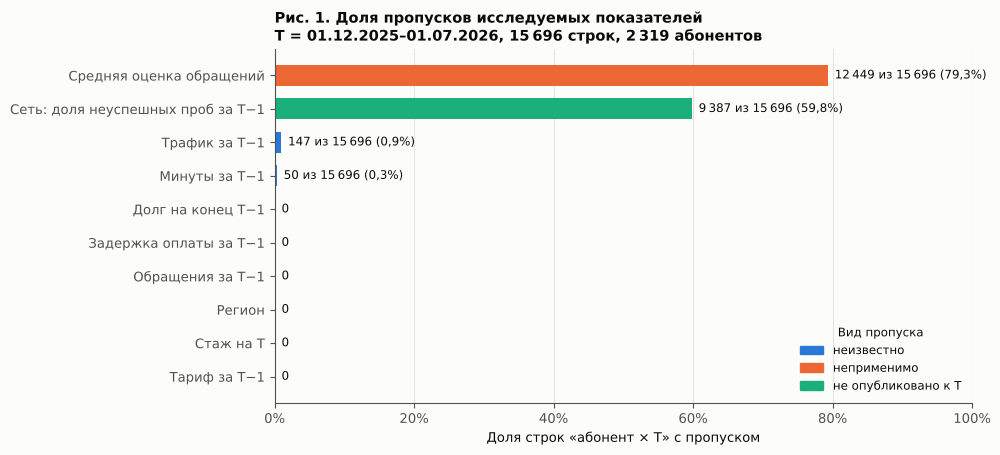

In [12]:
CATEGORY_COLORS = {"неизвестно": COLORS["s1"], "неприменимо": COLORS["s2"], "не опубликовано к T": COLORS["s3"]}

fig, ax = plt.subplots(figsize=(9, 4.6))
colors = [CATEGORY_COLORS.get(c, COLORS["muted"]) for c in missing.category]
ax.barh(missing.label, missing.missing_share, color=colors, height=0.62)
for y, row in missing.iterrows():
    text = "0" if row.n_missing == 0 else f"{fmt_int(row.n_missing)} из {fmt_int(row.n_rows)} ({fmt_pct(row.missing_share)})"
    ax.text(row.missing_share + 0.01, y, text, va="center", fontsize=8.5, color=COLORS["text"])
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(lambda x, _: fmt_pct(x, 0))
ax.grid(axis="y", visible=False)
ax.set_xlabel("Доля строк «абонент × T» с пропуском")
ax.set_title(f"Рис. 1. Доля пропусков исследуемых показателей\n"
             f"T = 01.12.2025–01.07.2026, {fmt_int(len(eda))} строк, {fmt_int(eda.customer_id.nunique())} абонентов",
             loc="left")
ax.legend(handles=[Patch(color=c, label=k) for k, c in CATEGORY_COLORS.items()], title="Вид пропуска",
          loc="lower right", frameon=False, fontsize=8.5, title_fontsize=8.5)
save_figure(fig, "fig1_missing")

### Распределения числовых показателей

Минимум, квартили, хвостовые квантили и максимум считаются только по известным значениям; `n_known` и `n_missing` показывают, сколько значений вошло в расчёт. Нули считаются отдельно: у долга, обращений и оплаты ноль — содержательное значение.

In [13]:
NUMERIC = ["traffic_gb", "voice_minutes", "closing_debt_rub", "opening_debt_rub", "charged_rub", "paid_rub",
           "payment_delay_days", "active_days", "support_count", "support_score_mean", "tenure_days"]
QUANTILES = {"q25": 0.25, "median": 0.5, "q75": 0.75, "q90": 0.9, "q99": 0.99}


def describe_numeric(values: pd.Series, name: str) -> dict:
    known = values.dropna().astype(float)
    row = {"indicator": name, "n_rows": len(values), "n_known": len(known), "n_missing": int(values.isna().sum()),
           "n_zero": int((known == 0).sum()), "zero_share_of_known": round((known == 0).mean(), 4),
           "mean": round(known.mean(), 2), "min": round(known.min(), 2)}
    row |= {k: round(known.quantile(q), 2) for k, q in QUANTILES.items()}
    row["max"] = round(known.max(), 2)
    return row


numeric_summary = pd.DataFrame(
    [describe_numeric(eda[c], c) for c in NUMERIC]
    + [describe_numeric(eda.closing_debt_rub[eda.closing_debt_rub > 0], "closing_debt_rub (>0)")])
write_csv(numeric_summary, TABLES / "numeric_summary.csv")
numeric_summary

,indicator,n_rows,n_known,n_missing,n_zero,zero_share_of_known,mean,min,q25,median,q75,q90,q99,max
0,traffic_gb,15696,15549,147,0,0.0000,31.17,0.15,12.67,23.07,41.54,65.26,126.46,289.44
1,voice_minutes,15696,15646,50,0,0.0000,318.67,1.00,133.00,250.00,432.00,666.00,1162.10,1755.00
2,closing_debt_rub,15696,15696,0,12035,0.7668,155.90,0.00,0.00,0.00,0.00,603.42,1783.50,5233.36
3,opening_debt_rub,15696,15696,0,12232,0.7793,142.93,0.00,0.00,0.00,0.00,502.96,1658.27,5233.36
4,charged_rub,15696,15696,0,0,0.0000,730.02,14.52,450.00,750.00,822.92,1200.00,1422.65,2195.03
5,paid_rub,15696,15696,0,1829,0.1165,717.05,0.00,450.00,690.18,916.91,1269.01,2464.62,6456.29
6,payment_delay_days,15696,15696,0,8705,0.5546,5.46,0.00,0.00,0.00,7.00,30.00,31.00,31.00
7,active_days,15696,15696,0,0,0.0000,29.87,1.00,30.00,30.00,31.00,31.00,31.00,31.00
8,support_count,15696,15696,0,10351,0.6595,0.45,0.00,0.00,0.00,1.00,1.00,3.00,6.00
9,support_score_mean,15696,3247,12449,0,0.0000,3.57,1.00,3.00,4.00,4.50,5.00,5.00,5.00


### Частоты категорий

Тариф берётся из строки биллинга за T−1 и может меняться между датами, поэтому `n_customers` по тарифам в сумме больше числа абонентов. Редкая категория — меньше 30 строк или меньше 1% строк.

In [14]:
CATEGORICAL = ["tariff", "region", "acquisition_channel", "customer_segment", "debt_group", "support_group",
               "tenure_group"]
frequencies = []
for col in CATEGORICAL:
    g = eda.groupby(col, observed=False).agg(n_observations=("customer_id", "size"),
                                            n_customers=("customer_id", "nunique"))
    for value, row in g.iterrows():
        frequencies.append({"field": col, "value": value, "n_observations": int(row.n_observations),
                            "share": round(row.n_observations / len(eda), 4), "n_customers": int(row.n_customers),
                            "rare": bool(0 < row.n_observations and (row.n_observations < 30 or row.n_observations / len(eda) < 0.01))})
frequencies = pd.DataFrame(frequencies)
for col in CATEGORICAL:
    require(frequencies.loc[frequencies.field == col, "n_observations"].sum() == len(eda), f"{col}: lost rows")
write_csv(frequencies, TABLES / "categorical_frequencies.csv")
print("Rare categories:", int(frequencies.rare.sum()), "| empty categories:",
      frequencies.loc[frequencies.n_observations == 0, ["field", "value"]].to_dict("records"))
frequencies

Rare categories: 0 | empty categories: [{'field': 'debt_group', 'value': 'неизвестен'}, {'field': 'support_group', 'value': 'неизвестно'}]


,field,value,n_observations,share,n_customers,rare
0,tariff,Basic,6239,0.3975,1009,False
1,tariff,Comfort,6286,0.4005,1044,False
2,tariff,Premium,3171,0.2020,549,False
3,region,Красноярский край,3027,0.1929,452,False
4,region,Москва,3197,0.2037,480,False
5,region,Московская область,3142,0.2002,468,False
6,region,Новосибирская область,3186,0.2030,465,False
7,region,Томская область,3144,0.2003,454,False
8,acquisition_channel,online,7401,0.4715,1101,False
9,acquisition_channel,partner,2516,0.1603,375,False


### Нули и экстремальные значения

Большое значение — повод проверить запись, а не удалить её. Для долга проверяется тождество словаря данных `closing = opening + charged − paid`: если оно выполняется, большой долг — накопленный за несколько месяцев, а не ошибка записи. Для трафика верхней границы в словаре нет; крупные значения сверяются с тарифом и начислениями.

In [15]:
ZERO_MEANING = [
    ("closing_debt_rub", "Долга на конец месяца T−1 нет"),
    ("paid_rub", "Оплаты в месяце T−1 не было"),
    ("payment_delay_days", "Оплата без задержки"),
    ("support_count", "Обращений в месяце T−1 не было (среди корректных и доступных к T)"),
    ("traffic_gb", "Нулевой трафик; пропуск — другое значение"),
    ("voice_minutes", "Нулевые минуты; пропуск — другое значение"),
]
zeros = pd.DataFrame([{"indicator": c, "n_known": int(eda[c].notna().sum()), "n_zero": int((eda[c] == 0).sum()),
                       "meaning": m} for c, m in ZERO_MEANING])
write_csv(zeros, TABLES / "zeros_meaning.csv")

identity_gap = (eda.opening_debt_rub + eda.charged_rub - eda.paid_rub - eda.closing_debt_rub).abs()
n_identity_broken = int((identity_gap > 0.01).sum())
record_check("debt identity closing = opening + charged - paid holds in eda rows", n_identity_broken == 0,
             f"rows violating by more than 0.01 rub: {n_identity_broken}")

EXTREME_CONTEXT = ["customer_id", "snapshot_at", "tariff", "monthly_fee_rub", "opening_debt_rub", "charged_rub",
                   "paid_rub", "closing_debt_rub", "payment_delay_days", "traffic_gb"]
extremes = pd.concat([
    eda.nlargest(5, "closing_debt_rub")[EXTREME_CONTEXT].assign(reason="5 наибольших долгов"),
    eda.nlargest(5, "traffic_gb")[EXTREME_CONTEXT].assign(reason="5 наибольших значений трафика"),
], ignore_index=True)
write_csv(extremes, TABLES / "extremes_review.csv")

debtors = eda[eda.closing_debt_rub > 0]
debt_is_one_fee = int((debtors.closing_debt_rub == debtors.monthly_fee_rub).sum())
top_traffic = eda.nlargest(int(eda.traffic_gb.notna().sum() * 0.01), "traffic_gb")
print(f"Debt identity broken: {n_identity_broken} rows of {len(eda)}.")
print(f"Debt equal to exactly one monthly fee: {debt_is_one_fee} of {len(debtors)} rows with debt > 0.")
print(f"Top 1% traffic ({len(top_traffic)} rows): tariffs {top_traffic.tariff.value_counts().to_dict()}, "
      f"charged above the fee in {int((top_traffic.charged_rub > top_traffic.monthly_fee_rub).sum())} rows.")
display(zeros)
extremes

Debt identity broken: 0 rows of 15696.
Debt equal to exactly one monthly fee: 729 of 3661 rows with debt > 0.
Top 1% traffic (155 rows): tariffs {'Premium': 147, 'Comfort': 8}, charged above the fee in 155 rows.


,indicator,n_known,n_zero,meaning
0,closing_debt_rub,15696,12035,Долга на конец месяца T−1 нет
1,paid_rub,15696,1829,Оплаты в месяце T−1 не было
2,payment_delay_days,15696,8705,Оплата без задержки
3,support_count,15696,10351,Обращений в месяце T−1 не было (среди корректн...
4,traffic_gb,15549,0,Нулевой трафик; пропуск — другое значение
5,voice_minutes,15646,0,Нулевые минуты; пропуск — другое значение


,customer_id,snapshot_at,tariff,monthly_fee_rub,opening_debt_rub,charged_rub,paid_rub,closing_debt_rub,payment_delay_days,traffic_gb,reason
0,C000994,2026-02-01 00:00:00+03:00,Premium,1200.0,3994.75,1238.61,0.00,5233.36,31,77.16,5 наибольших долгов
1,C001859,2026-07-01 00:00:00+03:00,Premium,1200.0,3147.04,1544.45,0.00,4691.49,30,137.95,5 наибольших долгов
2,C001360,2026-04-01 00:00:00+03:00,Premium,1200.0,2858.24,1210.77,0.00,4069.01,31,66.99,5 наибольших долгов
3,C001352,2026-06-01 00:00:00+03:00,Premium,1200.0,2777.70,1255.42,0.00,4033.12,31,81.81,5 наибольших долгов
4,C000994,2026-01-01 00:00:00+03:00,Premium,1200.0,2794.75,1200.00,0.00,3994.75,31,61.00,5 наибольших долгов
5,C000559,2025-12-01 00:00:00+03:00,Premium,1200.0,0.00,2195.03,2195.03,0.00,0,289.44,5 наибольших значений трафика
6,C001714,2026-03-01 00:00:00+03:00,Premium,1200.0,0.00,1657.87,1657.87,0.00,0,259.04,5 наибольших значений трафика
7,C001829,2026-07-01 00:00:00+03:00,Premium,1200.0,0.00,1746.23,1746.23,0.00,0,240.26,5 наибольших значений трафика
8,C001714,2026-04-01 00:00:00+03:00,Premium,1200.0,0.00,1777.42,1777.42,0.00,1,218.67,5 наибольших значений трафика
9,C001840,2026-04-01 00:00:00+03:00,Premium,1200.0,0.00,2072.91,2072.91,0.00,3,217.73,5 наибольших значений трафика


### Трафик и долг (рисунок 2)

Гистограммы показаны до 99-го процентиля, чтобы хвост не сжимал основную массу; число значений за этой границей и максимум подписаны, а боксплот под гистограммой показывает весь диапазон. У долга 0 — самое частое значение, поэтому распределение строится по строкам с долгом > 0, а доля нулей вынесена в подпись.

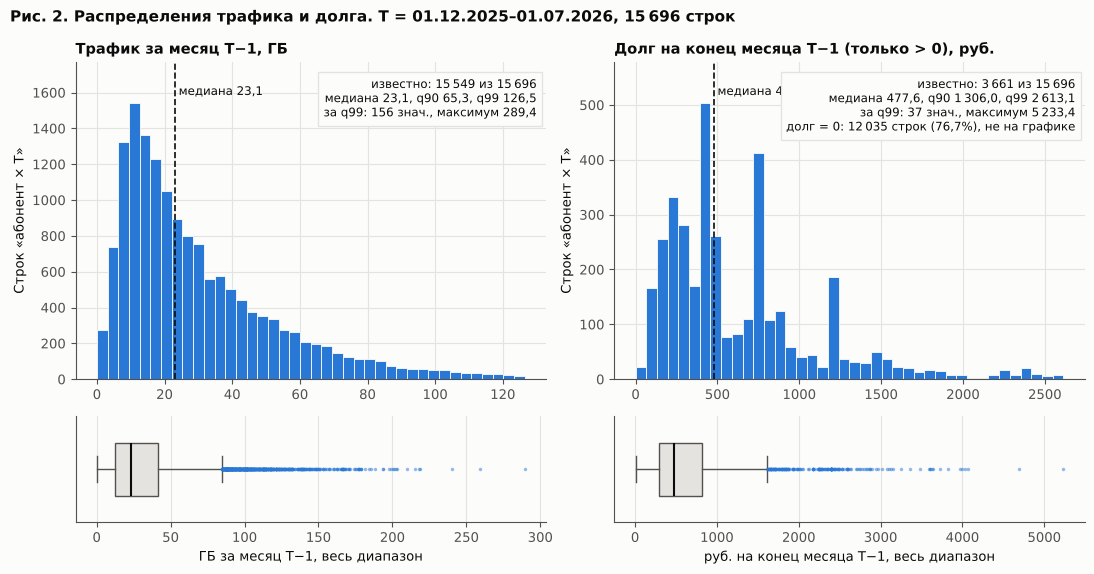

,indicator,n_rows,n_known,n_missing,n_zero,zero_share_of_known,mean,min,q25,median,q75,q90,q99,max
0,traffic_gb,15696,15549,147,0,0.0000,31.17,0.15,12.67,23.07,41.54,65.26,126.46,289.44
2,closing_debt_rub,15696,15696,0,12035,0.7668,155.90,0.00,0.00,0.00,0.00,603.42,1783.50,5233.36
11,closing_debt_rub (>0),3661,3661,0,0,0.0000,668.39,6.13,292.29,477.63,822.13,1306.05,2613.07,5233.36


In [16]:
def distribution_panel(ax_hist, ax_box, values: pd.Series, n_rows: int, unit: str, title: str, note: str,
                       bins: int = 40) -> pd.DataFrame:
    """Histogram up to q99 plus a full-range boxplot; returns the histogram bins for the table."""
    known = values.dropna().astype(float)
    q50, q90, q99 = known.quantile([0.5, 0.9, 0.99])
    counts, edges = np.histogram(known[known <= q99], bins=bins, range=(0, q99))
    ax_hist.bar(edges[:-1], counts, width=np.diff(edges), align="edge", color=COLORS["s1"],
                edgecolor=COLORS["surface"], linewidth=0.6)
    ax_hist.axvline(q50, color=COLORS["text"], linewidth=1.2, linestyle="--")
    ax_hist.text(q50, counts.max() * 1.02, f" медиана {fmt_num(q50)}", color=COLORS["text"], fontsize=8.5,
                 va="bottom")
    tail = int((known > q99).sum())
    stats = (f"известно: {fmt_int(len(known))} из {fmt_int(n_rows)}\n"
             f"медиана {fmt_num(q50)}, q90 {fmt_num(q90)}, q99 {fmt_num(q99)}\n"
             f"за q99: {fmt_int(tail)} знач., максимум {fmt_num(known.max())}" + (f"\n{note}" if note else ""))
    ax_hist.text(0.98, 0.95, stats, transform=ax_hist.transAxes, ha="right", va="top", fontsize=8.5,
                 color=COLORS["text"], bbox={"facecolor": COLORS["surface"], "edgecolor": COLORS["grid"]})
    ax_hist.set_title(title)
    ax_hist.set_ylabel("Строк «абонент × T»")
    ax_hist.set_ylim(0, counts.max() * 1.15)
    ax_box.boxplot(known, orientation="horizontal", widths=0.5, patch_artist=True,
                   boxprops={"facecolor": COLORS["grid"], "edgecolor": COLORS["muted"]},
                   medianprops={"color": COLORS["text"], "linewidth": 1.5},
                   whiskerprops={"color": COLORS["muted"]}, capprops={"color": COLORS["muted"]},
                   flierprops={"marker": "o", "markersize": 2.5, "markerfacecolor": COLORS["s1"],
                               "markeredgecolor": "none", "alpha": 0.5})
    ax_box.set_yticks([])
    ax_box.grid(axis="y", visible=False)
    ax_box.set_xlabel(f"{unit}, весь диапазон")
    return pd.DataFrame({"bin_left": edges[:-1].round(2), "bin_right": edges[1:].round(2), "count": counts})


debt = eda.closing_debt_rub
debt_zero = int((debt == 0).sum())
fig, axes = plt.subplots(2, 2, figsize=(11, 5.8), gridspec_kw={"height_ratios": [3, 1]})
traffic_bins = distribution_panel(axes[0, 0], axes[1, 0], eda.traffic_gb, len(eda), "ГБ за месяц T−1",
                                  "Трафик за месяц T−1, ГБ", "")
debt_bins = distribution_panel(axes[0, 1], axes[1, 1], debt[debt > 0], len(eda), "руб. на конец месяца T−1",
                               "Долг на конец месяца T−1 (только > 0), руб.",
                               f"долг = 0: {fmt_int(debt_zero)} строк ({fmt_pct(debt_zero / len(eda))}), не на графике")
fig.suptitle(f"Рис. 2. Распределения трафика и долга. T = 01.12.2025–01.07.2026, {fmt_int(len(eda))} строк",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
save_figure(fig, "fig2_traffic_debt")

fig2_summary = numeric_summary[numeric_summary.indicator.isin(["traffic_gb", "closing_debt_rub",
                                                               "closing_debt_rub (>0)"])]
write_csv(fig2_summary, TABLES / "fig2_distribution_summary.csv")
write_csv(pd.concat([traffic_bins.assign(indicator="traffic_gb"), debt_bins.assign(indicator="closing_debt_rub (>0)")],
                    ignore_index=True), TABLES / "fig2_histogram_bins.csv")
fig2_summary

*Шаг 3. Описание данных*

---

## Шаг 4. Связи с будущим оттоком

Доля оттока считается по строкам «абонент × T»: `churn_rate = n_churn / n_observations`. Один абонент входит в знаменатель на каждой дате, где он в активной базе, поэтому рядом всегда показано `n_customers`. Строки с неизвестной меткой в знаменатель не входят (на датах EDA их 0). Группы с неизвестным значением признака показаны отдельно, даже пустые. Группа меньше 30 строк помечается `small_group` — это учебный ориентир, а не граница надёжности.

Все групповые таблицы строит одна функция `churn_by`, поэтому числители и знаменатели везде считаются одинаково.

In [17]:
def churn_by(df: pd.DataFrame, by: list[str]) -> pd.DataFrame:
    """Churn per group of rows 'customer x T'; empty categories are kept with zero counts."""
    out = (df.groupby(by, observed=False)
           .agg(n_observations=("churn_target", "size"), n_customers=("customer_id", "nunique"),
                n_churn=("churn_target", "sum"))
           .reset_index())
    out["n_churn"] = out.n_churn.astype(int)
    out["churn_rate"] = (out.n_churn / out.n_observations.where(out.n_observations > 0)).round(6)
    out["small_group"] = out.n_observations.between(1, 29)
    return out


def label_T(ts: pd.Series) -> pd.Series:
    return ts.dt.strftime("%m.%Y")


churn_T = churn_by(eda, ["snapshot_at"])
churn_debt = churn_by(eda, ["debt_group"])
churn_support = churn_by(eda, ["support_group"])
churn_tenure = churn_by(eda, ["tenure_group"])
churn_tenure_debt = churn_by(eda, ["tenure_group", "debt_group"])
churn_tariff = churn_by(eda, ["tariff"])
churn_region = churn_by(eda, ["region"])

display(churn_T, churn_debt, churn_support, churn_tenure)

,snapshot_at,n_observations,n_customers,n_churn,churn_rate,small_group
0,2025-12-01 00:00:00+03:00,1969,1969,48,0.024378,False
1,2026-01-01 00:00:00+03:00,1971,1971,50,0.025368,False
2,2026-02-01 00:00:00+03:00,1971,1971,52,0.026383,False
3,2026-03-01 00:00:00+03:00,1969,1969,54,0.027425,False
4,2026-04-01 00:00:00+03:00,1965,1965,56,0.028499,False
5,2026-05-01 00:00:00+03:00,1959,1959,58,0.029607,False
6,2026-06-01 00:00:00+03:00,1951,1951,60,0.030753,False
7,2026-07-01 00:00:00+03:00,1941,1941,62,0.031942,False


,debt_group,n_observations,n_customers,n_churn,churn_rate,small_group
0,>0,3661,1784,276,0.075389,False
1,=0,12035,2241,164,0.013627,False
2,неизвестен,0,0,0,<NA>,False


,support_group,n_observations,n_customers,n_churn,churn_rate,small_group
0,0,10351,2278,278,0.026857,False
1,1,4018,1867,122,0.030363,False
2,≥2,1327,962,40,0.030143,False
3,неизвестно,0,0,0,<NA>,False


,tenure_group,n_observations,n_customers,n_churn,churn_rate,small_group
0,<90,1097,445,40,0.036463,False
1,90–364,1808,476,61,0.033739,False
2,≥365,12791,1810,339,0.026503,False


### Динамика по датам T (рисунок 3)

Два отдельных графика с общей осью дат: доля оттока и размер активной базы. Совмещать их на двух шкалах одной панели нельзя — наклоны двух шкал можно подогнать к любому выводу.

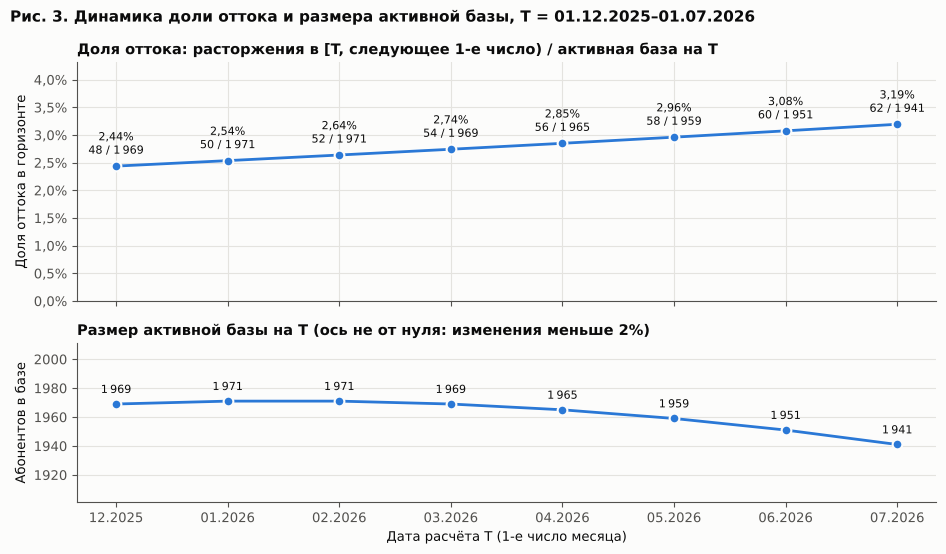

In [18]:
x = np.arange(len(churn_T))
fig, (ax_rate, ax_base) = plt.subplots(2, 1, figsize=(9.5, 5.6), sharex=True, gridspec_kw={"height_ratios": [3, 2]})

ax_rate.plot(x, churn_T.churn_rate, color=COLORS["s1"], linewidth=2, marker="o", markersize=7,
             markeredgecolor=COLORS["surface"], markeredgewidth=1.5)
for i, row in churn_T.iterrows():
    ax_rate.annotate(f"{fmt_pct(row.churn_rate, 2)}\n{row.n_churn} / {fmt_int(row.n_observations)}", (i, row.churn_rate),
                     textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8, color=COLORS["text"])
ax_rate.set_ylim(0, churn_T.churn_rate.max() * 1.35)
ax_rate.yaxis.set_major_formatter(lambda v, _: fmt_pct(v, 1))
ax_rate.set_ylabel("Доля оттока в горизонте")
ax_rate.set_title("Доля оттока: расторжения в [T, следующее 1-е число) / активная база на T")

ax_base.plot(x, churn_T.n_observations, color=COLORS["s1"], linewidth=2, marker="o", markersize=7,
             markeredgecolor=COLORS["surface"], markeredgewidth=1.5)
for i, row in churn_T.iterrows():
    ax_base.annotate(fmt_int(row.n_observations), (i, row.n_observations), textcoords="offset points",
                     xytext=(0, 8), ha="center", fontsize=8)
ax_base.set_ylim(churn_T.n_observations.min() - 40, churn_T.n_observations.max() + 40)
ax_base.set_ylabel("Абонентов в базе")
ax_base.set_title("Размер активной базы на T (ось не от нуля: изменения меньше 2%)")
ax_base.grid(axis="x", visible=False)
ax_base.set_xticks(x, label_T(churn_T.snapshot_at))
ax_base.set_xlabel("Дата расчёта T (1-е число месяца)")
fig.suptitle("Рис. 3. Динамика доли оттока и размера активной базы, T = 01.12.2025–01.07.2026",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
save_figure(fig, "fig3_churn_by_T")
write_csv(churn_T, TABLES / "fig3_churn_by_T.csv")

### Долг и обращения (рисунок 4)

Группы заданы на шаге 1: долг на конец месяца T−1 `>0` / `=0` / неизвестен; обращения, созданные в T−1 и известные к T, `0` / `1` / `≥2` / неизвестно. Пустые группы неизвестных значений остаются на графике с подписью `n = 0`.

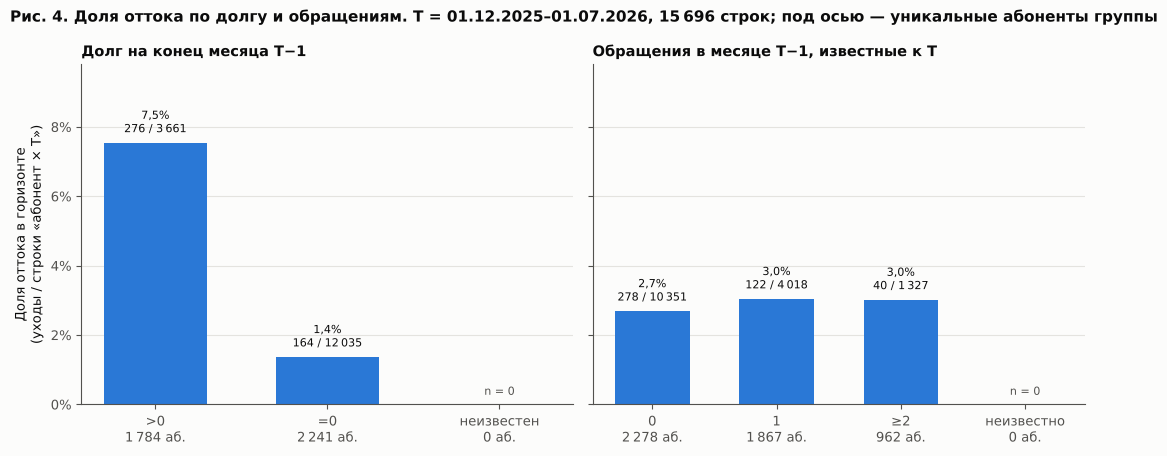

In [19]:
def rate_bars(ax, table: pd.DataFrame, group_col: str, title: str, color: str = COLORS["s1"]) -> None:
    """Churn rate per group with numerator/denominator on the bar and group size under the axis."""
    x = np.arange(len(table))
    rates = table.churn_rate.fillna(0)
    ax.bar(x, rates, width=0.6, color=color)
    for i, row in table.iterrows():
        if row.n_observations == 0:
            ax.text(i, 0.002, "n = 0", ha="center", va="bottom", fontsize=8, color=COLORS["muted"])
            continue
        flag = "\nмало строк" if row.small_group else ""
        ax.text(i, row.churn_rate + 0.002, f"{fmt_pct(row.churn_rate)}\n{row.n_churn} / {fmt_int(row.n_observations)}{flag}",
                ha="center", va="bottom", fontsize=8)
    ticks = [f"{row[group_col]}\n{fmt_int(row.n_customers)} аб." for _, row in table.iterrows()]
    ax.set_xticks(x, ticks)
    ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_formatter(lambda v, _: fmt_pct(v, 0))
    ax.set_title(title)


fig, (ax_d, ax_s) = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
rate_bars(ax_d, churn_debt, "debt_group", "Долг на конец месяца T−1")
rate_bars(ax_s, churn_support, "support_group", "Обращения в месяце T−1, известные к T")
top = max(churn_debt.churn_rate.max(), churn_support.churn_rate.max())
ax_d.set_ylim(0, top * 1.3)
ax_d.set_ylabel("Доля оттока в горизонте\n(уходы / строки «абонент × T»)")
fig.suptitle(f"Рис. 4. Доля оттока по долгу и обращениям. T = 01.12.2025–01.07.2026, {fmt_int(len(eda))} строк; "
             f"под осью — уникальные абоненты группы", x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
save_figure(fig, "fig4_churn_by_debt_support")
write_csv(pd.concat([churn_debt.rename(columns={"debt_group": "group"}).assign(factor="debt_group"),
                     churn_support.rename(columns={"support_group": "group"}).assign(factor="support_group")],
                    ignore_index=True)[["factor", "group", "n_observations", "n_customers", "n_churn", "churn_rate",
                                        "small_group"]],
          TABLES / "fig4_churn_by_debt_support.csv")

### Стаж и проверка альтернативного объяснения (рисунок 5)

Сегмент для H4 — стаж на T с границами 90 и 365 дней. Различие по стажу может объясняться составом групп: если у новых абонентов чаще долг, то стаж лишь повторяет связь с долгом. Поэтому справа то же сравнение повторено внутри групп долга.

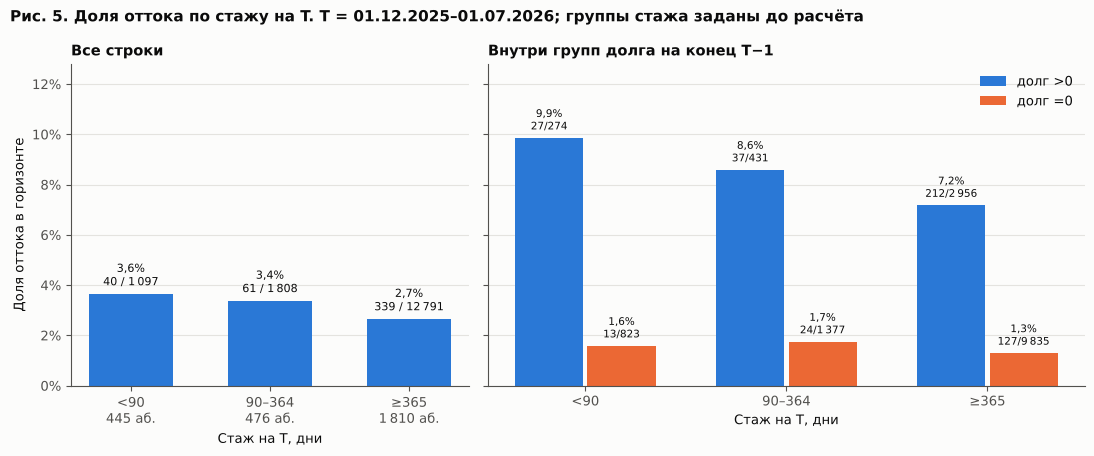

,tariff,n_observations,n_customers,n_churn,churn_rate,small_group
0,Basic,6239,1009,155,0.024844,False
1,Comfort,6286,1044,186,0.02959,False
2,Premium,3171,549,99,0.03122,False


,region,n_observations,n_customers,n_churn,churn_rate,small_group
0,Красноярский край,3027,452,97,0.032045,False
1,Москва,3197,480,101,0.031592,False
2,Московская область,3142,468,83,0.026416,False
3,Новосибирская область,3186,465,78,0.024482,False
4,Томская область,3144,454,81,0.025763,False


In [20]:
fig, (ax_t, ax_td) = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True,
                                  gridspec_kw={"width_ratios": [2, 3]})
rate_bars(ax_t, churn_tenure, "tenure_group", "Все строки")

DEBT_SERIES = {">0": COLORS["s1"], "=0": COLORS["s2"]}
width = 0.36
x = np.arange(len(TENURE_GROUPS))
for k, (group, color) in enumerate(DEBT_SERIES.items()):
    part = churn_tenure_debt[churn_tenure_debt.debt_group == group].set_index("tenure_group").loc[TENURE_GROUPS]
    pos = x + (k - 0.5) * width
    ax_td.bar(pos, part.churn_rate, width=width * 0.94, color=color, label=f"долг {group}")
    for p, (_, row) in zip(pos, part.iterrows()):
        flag = "\nмало" if row.small_group else ""
        ax_td.text(p, row.churn_rate + 0.002, f"{fmt_pct(row.churn_rate)}\n{row.n_churn}/{fmt_int(row.n_observations)}{flag}",
                   ha="center", va="bottom", fontsize=7.5)
ax_td.set_xticks(x, [f"{g}" for g in TENURE_GROUPS])
ax_td.grid(axis="x", visible=False)
ax_td.set_title("Внутри групп долга на конец T−1")
ax_td.legend(frameon=False, loc="upper right")
ax_t.set_ylim(0, churn_tenure_debt.churn_rate.max() * 1.3)
ax_t.set_ylabel("Доля оттока в горизонте")
for ax in (ax_t, ax_td):
    ax.set_xlabel("Стаж на T, дни")
fig.suptitle("Рис. 5. Доля оттока по стажу на T. T = 01.12.2025–01.07.2026; группы стажа заданы до расчёта",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
save_figure(fig, "fig5_churn_by_tenure")
write_csv(pd.concat([churn_tenure.assign(debt_group="все"), churn_tenure_debt], ignore_index=True)
          [["tenure_group", "debt_group", "n_observations", "n_customers", "n_churn", "churn_rate", "small_group"]],
          TABLES / "fig5_churn_by_tenure.csv")
write_csv(churn_tariff, TABLES / "churn_by_tariff.csv")
write_csv(churn_region, TABLES / "churn_by_region.csv")
display(churn_tariff, churn_region)

### Связь с долгом внутри месяцев, тарифов и групп стажа

Если разница между `>0` и `=0` держится внутри каждого среза, её нельзя объяснить только тем, что должники чаще встречаются в каком-то месяце, тарифе или группе стажа. Это проверка устойчивости связи, а не доказательство причины.

In [21]:
def within_strata(df: pd.DataFrame, stratum: str) -> pd.DataFrame:
    """Debt >0 vs =0 inside each value of another field."""
    t = churn_by(df[df.debt_group.isin(["=0", ">0"])], [stratum, "debt_group"])
    t = t[t.debt_group.isin(["=0", ">0"])]
    wide = t.pivot(index=stratum, columns="debt_group", values=["n_observations", "n_churn", "churn_rate"]).astype(float)
    out = pd.DataFrame({
        "stratum_field": stratum, "stratum": wide.index.astype(str),
        "n_obs_debt": wide[("n_observations", ">0")].values, "n_churn_debt": wide[("n_churn", ">0")].values,
        "rate_debt": wide[("churn_rate", ">0")].values,
        "n_obs_no_debt": wide[("n_observations", "=0")].values, "n_churn_no_debt": wide[("n_churn", "=0")].values,
        "rate_no_debt": wide[("churn_rate", "=0")].values})
    out = out.astype({c: int for c in ["n_obs_debt", "n_churn_debt", "n_obs_no_debt", "n_churn_no_debt"]})
    out["rate_ratio"] = (out.rate_debt / out.rate_no_debt).round(2)
    out["small_group"] = (out.n_obs_debt < 30) | (out.n_obs_no_debt < 30)
    return out


strata = pd.concat([within_strata(eda.assign(T=eda.snapshot_at.dt.strftime("%Y-%m-%d")), "T"),
                    within_strata(eda, "tariff"), within_strata(eda, "tenure_group"),
                    within_strata(eda, "region")], ignore_index=True)
write_csv(strata, TABLES / "debt_within_strata.csv")
print(f"Debt >0 has the higher churn rate in {int((strata.rate_debt > strata.rate_no_debt).sum())} "
      f"of {len(strata)} strata; rate ratio from {strata.rate_ratio.min()} to {strata.rate_ratio.max()}.")
strata

Debt >0 has the higher churn rate in 19 of 19 strata; rate ratio from 3.93 to 7.46.


,stratum_field,stratum,n_obs_debt,n_churn_debt,rate_debt,n_obs_no_debt,n_churn_no_debt,rate_no_debt,rate_ratio,small_group
0,T,2025-12-01,455,26,0.057143,1514,22,0.014531,3.93,False
1,T,2026-01-01,466,33,0.070815,1505,17,0.011296,6.27,False
2,T,2026-02-01,444,30,0.067568,1527,22,0.014407,4.69,False
3,T,2026-03-01,449,34,0.075724,1520,20,0.013158,5.75,False
4,T,2026-04-01,468,38,0.081197,1497,18,0.012024,6.75,False
5,T,2026-05-01,450,40,0.088889,1509,18,0.011928,7.45,False
6,T,2026-06-01,492,36,0.073171,1459,24,0.016450,4.45,False
7,T,2026-07-01,437,39,0.089245,1504,23,0.015293,5.84,False
8,tariff,Basic,1408,89,0.063210,4831,66,0.013662,4.63,False
9,tariff,Comfort,1506,118,0.078353,4780,68,0.014226,5.51,False


### Ушедшие и оставшиеся: обратное сравнение

Тот же вопрос с другой стороны: как распределены долг и обращения у строк, где абонент ушёл в горизонте, и у строк, где остался.

In [22]:
COMPARE = ["closing_debt_rub", "payment_delay_days", "support_count", "support_network_count", "traffic_gb",
           "voice_minutes", "charged_rub", "tenure_days"]
rows = []
for value, part in eda.groupby("churn_target"):
    for col in COMPARE:
        known = part[col].dropna().astype(float)
        rows.append({"churn_target": int(value), "indicator": col, "n_rows": len(part), "n_known": len(known),
                     "share_positive": round((known > 0).mean(), 4), "mean": round(known.mean(), 2),
                     "median": round(known.median(), 2), "q75": round(known.quantile(0.75), 2),
                     "q90": round(known.quantile(0.9), 2)})
churners_vs_stayers = pd.DataFrame(rows)
write_csv(churners_vs_stayers, TABLES / "churners_vs_stayers.csv")
churners_vs_stayers.pivot(index="indicator", columns="churn_target",
                          values=["n_known", "share_positive", "median", "q90"])

n_known        share_positive          median               q90         
churn_target                 0      1              0       1       0        1        0        1
indicator                                                                                      
charged_rub            15256.0  440.0         1.0000  1.0000   750.0   750.00  1200.00  1200.00
closing_debt_rub       15256.0  440.0         0.2219  0.6273     0.0   440.96   508.15  1318.95
payment_delay_days     15256.0  440.0         0.4375  0.7205     0.0    14.00    28.00    31.00
support_count          15256.0  440.0         0.3397  0.3682     0.0     0.00     1.00     1.00
support_network_count  15256.0  440.0         0.1614  0.1591     0.0     0.00     1.00     1.00
tenure_days            15256.0  440.0         1.0000  1.0000  1222.0  1217.00  2350.00  2314.60
traffic_gb             15112.0  437.0         1.0000  1.0000    23.1    21.70    65.24    67.15
voice_minutes          15207.0  439.0         1.0000  1.0000   251.0   222.00   667.00   602.40

### Интервалы с учётом повторных наблюдений

Простой интервал для доли считает строки независимыми. Здесь один абонент даёт в среднем почти 7 строк, и его исходы связаны, поэтому такой интервал слишком узкий. Кластерный бутстреп пересэмплирует **абонентов** целиком со всеми их строками. Для сравнения рядом показан наивный интервал. Это дополнительный инструмент: выводы по гипотезам опираются на таблицы групп, а интервал показывает, насколько разница устойчива к составу абонентов.

In [23]:
BOOTSTRAP_REPS = 2000
BOOTSTRAP_SEED = 20261024


def cluster_bootstrap_diff(df: pd.DataFrame, group_col: str, a: str, b: str) -> dict:
    """Difference of churn rates a - b with a 95% interval: customers resampled with all their rows."""
    sub = df[df[group_col].isin([a, b])]
    per_customer = (sub.assign(is_a=sub[group_col] == a)
                    .groupby(["customer_id", "is_a"]).churn_target.agg(["size", "sum"]).unstack(fill_value=0))
    obs_a, obs_b = per_customer[("size", True)].to_numpy(), per_customer[("size", False)].to_numpy()
    churn_a, churn_b = per_customer[("sum", True)].to_numpy(), per_customer[("sum", False)].to_numpy()
    n = len(per_customer)
    weights = np.random.default_rng(BOOTSTRAP_SEED).multinomial(n, np.full(n, 1 / n), size=BOOTSTRAP_REPS)
    diffs = weights @ churn_a / (weights @ obs_a) - weights @ churn_b / (weights @ obs_b)
    rate_a, rate_b = churn_a.sum() / obs_a.sum(), churn_b.sum() / obs_b.sum()
    naive_se = np.sqrt(rate_a * (1 - rate_a) / obs_a.sum() + rate_b * (1 - rate_b) / obs_b.sum())
    return {"factor": group_col, "group_a": a, "group_b": b, "rate_a": round(rate_a, 5), "rate_b": round(rate_b, 5),
            "diff": round(rate_a - rate_b, 5),
            "cluster_ci_low": round(np.quantile(diffs, 0.025), 5), "cluster_ci_high": round(np.quantile(diffs, 0.975), 5),
            "naive_ci_low": round(rate_a - rate_b - 1.96 * naive_se, 5),
            "naive_ci_high": round(rate_a - rate_b + 1.96 * naive_se, 5),
            "n_customers": n, "reps": BOOTSTRAP_REPS}


eda_ci = eda.assign(support_any=np.where(eda.support_count > 0, "≥1", "0"))
intervals = pd.DataFrame([
    cluster_bootstrap_diff(eda_ci, "debt_group", ">0", "=0"),
    cluster_bootstrap_diff(eda_ci, "support_any", "≥1", "0"),
    cluster_bootstrap_diff(eda_ci, "tenure_group", "<90", "≥365"),
    cluster_bootstrap_diff(eda_ci, "tenure_group", "90–364", "≥365"),
])
write_csv(intervals, TABLES / "rate_difference_intervals.csv")
intervals

,factor,group_a,group_b,rate_a,rate_b,diff,cluster_ci_low,cluster_ci_high,naive_ci_low,naive_ci_high,n_customers,reps
0,debt_group,>0,=0,0.07539,0.01363,0.06176,0.05266,0.07068,0.05296,0.07056,2319,2000
1,support_any,≥1,0,0.03031,0.02686,0.00345,-0.00208,0.00892,-0.00210,0.00900,2319,2000
2,tenure_group,<90,≥365,0.03646,0.02650,0.00996,-0.00094,0.02146,-0.00148,0.02140,2255,2000
3,tenure_group,90–364,≥365,0.03374,0.02650,0.00724,-0.00119,0.01642,-0.00154,0.01601,2144,2000


### Корреляции числовых показателей

Ранговая корреляция Спирмена по числовым показателям строки. Идентификаторы, коды категорий и служебные флаги исключены. Корреляция с `churn_target` здесь — описательная мера на повторных строках, не тест значимости. Пропуски исключаются попарно.

In [24]:
CORR_COLUMNS = ["closing_debt_rub", "opening_debt_rub", "payment_delay_days", "paid_rub", "charged_rub",
                "traffic_gb", "voice_minutes", "active_days", "support_count", "support_network_count",
                "tenure_days", "churn_target"]
correlation = eda[CORR_COLUMNS].astype(float).corr(method="spearman").round(3)
write_csv(correlation.reset_index(names="indicator"), TABLES / "spearman_correlation.csv")
correlation

,closing_debt_rub,opening_debt_rub,payment_delay_days,paid_rub,charged_rub,traffic_gb,voice_minutes,active_days,support_count,support_network_count,tenure_days,churn_target
closing_debt_rub,1.000,0.107,0.792,-0.578,0.040,0.033,0.018,0.009,0.038,0.028,-0.003,0.171
opening_debt_rub,0.107,1.000,0.065,0.301,0.047,0.035,0.018,0.018,0.283,0.194,0.026,0.035
payment_delay_days,0.792,0.065,1.000,-0.475,0.002,0.004,0.004,0.009,0.022,0.017,-0.007,0.132
paid_rub,-0.578,0.301,-0.475,1.000,0.608,0.491,0.359,0.043,0.100,0.072,0.058,-0.112
charged_rub,0.040,0.047,0.002,0.608,1.000,0.832,0.581,0.059,0.030,0.025,0.068,0.007
traffic_gb,0.033,0.035,0.004,0.491,0.832,1.000,0.574,0.033,0.026,0.028,0.048,-0.016
voice_minutes,0.018,0.018,0.004,0.359,0.581,0.574,1.000,0.050,0.014,0.004,0.055,-0.024
active_days,0.009,0.018,0.009,0.043,0.059,0.033,0.050,1.000,0.026,0.023,0.081,-0.002
support_count,0.038,0.283,0.022,0.100,0.030,0.026,0.014,0.026,1.000,0.636,0.030,0.010
support_network_count,0.028,0.194,0.017,0.072,0.025,0.028,0.004,0.023,0.636,1.000,0.007,-0.001


### Проверки групповых расчётов

Числители и знаменатели каждой групповой таблицы должны восстанавливаться из `eda_sample`: суммы по группам равны числу строк и уходов, а одна группа пересчитывается прямой фильтрацией без `churn_by`.

In [25]:
total_rows, total_churn = len(eda), int(eda.churn_target.sum())
group_tables = {"T": churn_T, "debt": churn_debt, "support": churn_support, "tenure": churn_tenure,
                "tenure x debt": churn_tenure_debt, "tariff": churn_tariff, "region": churn_region}
sums_ok = all(t.n_observations.sum() == total_rows and t.n_churn.sum() == total_churn for t in group_tables.values())
record_check("group numerators and denominators add up to eda_sample", sums_ok,
             f"{len(group_tables)} tables; each sums to {total_rows} rows and {total_churn} churn")

direct = eda_sample[(eda_sample.churn_target.notna()) & (eda_sample.closing_debt_rub > 0)]
row = churn_debt.set_index("debt_group").loc[">0"]
direct_ok = (len(direct) == row.n_observations and int(direct.churn_target.sum()) == row.n_churn
             and direct.customer_id.nunique() == row.n_customers)
record_check("debt >0 group recomputed directly from eda_sample", direct_ok,
             f"{len(direct)} rows, {int(direct.churn_target.sum())} churn, {direct.customer_id.nunique()} customers")

known_debt_rows = int(eda.debt_group.isin(["=0", ">0"]).sum())
strata_ok = all(
    strata[strata.stratum_field == f][["n_obs_debt", "n_obs_no_debt"]].to_numpy().sum() == known_debt_rows
    for f in ["T", "tariff", "tenure_group", "region"])
record_check("debt-within-strata tables cover every row with known debt once", strata_ok,
             f"T, tariff, tenure_group, region; {known_debt_rows} rows each")

*Шаг 4. Связи с будущим оттоком*

---

## Шаг 5. Новые источники и контекст

Сетевой отчёт — одна строка на регион и месяц измерений. Доля неуспешных проб = `failed_probe_count / probe_count`. При объединении регионов делятся **суммы**: `sum(failed) / sum(probe)`; среднее региональных долей так не считается, потому что число проб в регионах разное. Общие p50/p90 из региональных квантилей не выводятся.

Для снимка T используется отчёт региона абонента за месяц T−1, и только если `report_available_at ≤ snapshot_at`. Иначе значение на T неизвестно; отчёт следующего месяца не подставляется. Сетевые поля в `eda_sample` не добавляются: они лежат в отдельной таблице доступности с ключом `(region, measurement_month, snapshot_at)`.

Календарь `business_context` к абонентам не присоединяется. Он используется только как подписи к графику и как таблица «когда сообщение стало известно».

In [26]:
network["failed_probe_rate"] = network.failed_probe_count / network.probe_count
network["publication_delay_hours"] = (
    (network.report_available_at - (network.measurement_month + pd.DateOffset(months=1)).map(snapshot_moment))
    .dt.total_seconds() / 3600)

pooled = (network.groupby("measurement_month")
          .agg(probe_count=("probe_count", "sum"), failed_probe_count=("failed_probe_count", "sum"),
               mean_of_region_rates=("failed_probe_rate", "mean"))
          .reset_index())
pooled["failed_probe_rate"] = pooled.failed_probe_count / pooled.probe_count
pooled["region"] = "Все регионы"

network_rates = pd.concat([
    network[["region", "measurement_month", "probe_count", "failed_probe_count", "failed_probe_rate",
             "download_mbps_p50", "download_mbps_p90", "report_available_at", "publication_delay_hours"]],
    pooled[["region", "measurement_month", "probe_count", "failed_probe_count", "failed_probe_rate"]],
], ignore_index=True).round({"failed_probe_rate": 6})
write_csv(network_rates, TABLES / "network_failed_rate_by_region_month.csv")

record_check("pooled failed rate uses sum(failed) / sum(probe)",
             bool(np.allclose(pooled.failed_probe_rate,
                              network.groupby("measurement_month").failed_probe_count.sum().values
                              / network.groupby("measurement_month").probe_count.sum().values)),
             f"max gap to the naive mean of region rates: "
             f"{(pooled.failed_probe_rate - pooled.mean_of_region_rates).abs().max() * 100:.3f} p.p.")

print("Publication delay after the month end, hours:", network.publication_delay_hours.value_counts().sort_index().to_dict())
network.pivot(index="measurement_month", columns="region", values="failed_probe_rate").mul(100).round(2)

Publication delay after the month end, hours: {0.0: 24, 24.0: 12, 36.0: 12, 48.0: 12}


region,Красноярский край,Москва,Московская область,Новосибирская область,Томская область
measurement_month,,,,,
2025-09-01,1.73,1.54,2.23,2.67,2.29
2025-10-01,1.41,1.24,1.77,2.74,2.56
2025-11-01,0.94,2.16,1.55,1.51,1.96
2025-12-01,0.66,1.18,1.63,2.32,2.47
2026-01-01,0.9,1.96,5.52,1.59,2.55
2026-02-01,0.99,1.38,5.79,2.34,3.01
2026-03-01,1.58,2.09,1.34,1.68,2.21
2026-04-01,1.65,1.44,1.93,5.03,2.48
2026-05-01,1.06,2.19,1.66,4.82,2.81


### Таблица доступности сетевых отчётов на T

In [27]:
def latest_known_report(network: pd.DataFrame, region: str, snapshot_at: pd.Timestamp) -> pd.Series:
    """The most recent report of a region already published at snapshot_at."""
    known = network[(network.region == region) & (network.report_available_at <= snapshot_at)]
    return known.loc[known.measurement_month.idxmax()]


network_at_T = availability[["region", "measurement_month", "snapshot_at", "report_available_at",
                             "report_known_at_T", "probe_count", "failed_probe_count"]].copy()
network_at_T["hours_after_T"] = (network_at_T.report_available_at - network_at_T.snapshot_at).dt.total_seconds() / 3600
network_at_T["failed_probe_rate_known_at_T"] = (
    (network_at_T.failed_probe_count / network_at_T.probe_count).where(network_at_T.report_known_at_T).round(6))
latest = [latest_known_report(network, r.region, r.snapshot_at) for r in network_at_T.itertuples()]
network_at_T["latest_known_measurement_month"] = [r.measurement_month for r in latest]
network_at_T["latest_known_failed_rate"] = [round(r.failed_probe_rate, 6) for r in latest]
network_at_T["latest_known_lag_months"] = [
    (s.year - m.year) * 12 + s.month - m.month
    for s, m in zip(network_at_T.snapshot_at, network_at_T.latest_known_measurement_month)]
write_csv(network_at_T, OUTPUT / "network_availability.csv")

by_T_known = (network_at_T.groupby("snapshot_at").report_known_at_T.agg(known="sum", total="size").reset_index())
by_region_known = network_at_T.groupby("region").report_known_at_T.agg(known="sum", total="size").reset_index()
write_csv(pd.concat([by_T_known.assign(level="snapshot_at"), by_region_known.assign(level="region")]),
          TABLES / "network_availability_summary.csv")
print(f"Reports for month T-1 known at T: {int(network_at_T.report_known_at_T.sum())} of {len(network_at_T)}; "
      f"latest known report lag in months: {network_at_T.latest_known_lag_months.value_counts().sort_index().to_dict()}")
display(by_T_known, by_region_known)

Reports for month T-1 known at T: 16 of 40; latest known report lag in months: {1: 16, 2: 24}


,snapshot_at,known,total
0,2025-12-01 00:00:00+03:00,2,5
1,2026-01-01 00:00:00+03:00,2,5
2,2026-02-01 00:00:00+03:00,2,5
3,2026-03-01 00:00:00+03:00,2,5
4,2026-04-01 00:00:00+03:00,2,5
5,2026-05-01 00:00:00+03:00,2,5
6,2026-06-01 00:00:00+03:00,2,5
7,2026-07-01 00:00:00+03:00,2,5


,region,known,total
0,Красноярский край,2,8
1,Москва,4,8
2,Московская область,3,8
3,Новосибирская область,3,8
4,Томская область,4,8


In [28]:
dups = int(network_at_T.duplicated(["region", "measurement_month", "snapshot_at"]).sum())
record_check("network availability key (region, measurement_month, snapshot_at) is unique", dups == 0,
             f"{len(network_at_T)} rows, duplicates: {dups}")

late = network_at_T[network_at_T.report_available_at > network_at_T.snapshot_at]
late_ok = (~late.report_known_at_T).all() and late.failed_probe_rate_known_at_T.isna().all()
latest_ok = (network_at_T.latest_known_measurement_month <= network_at_T.measurement_month).all()
record_check("a network report published after T is unknown at T", bool(late_ok and latest_ok),
             f"{len(late)} late reports have no value at T; latest known report never later than month T-1")

# Synthetic boundary: a report published exactly at T is known, one minute later is not
T = pd.Timestamp("2026-03-01")
probe = pd.DataFrame({"region": ["R_on_T", "R_after_T"], "measurement_month": [pd.Timestamp("2026-02-01")] * 2,
                      "report_available_at": [snapshot_moment(T), pd.Timestamp(f"{T:%Y-%m-%d}T00:01:00{MSK}")],
                      "probe_count": [100, 100], "failed_probe_count": [1, 1]})
probe_known = network_availability(probe, pd.DatetimeIndex([T])).set_index("region").report_known_at_T
record_check("synthetic report: published at T is known, T + 1 minute is not",
             bool(probe_known["R_on_T"] and not probe_known["R_after_T"]), "report_available_at <= snapshot_at")

### Календарь событий: когда сообщение стало известно

In [29]:
context_view = context.copy()
context_view["days_from_period_end_to_announcement"] = (
    (context_view.announced_at.dt.tz_localize(None).dt.normalize() - context_view.event_end).dt.days)
period_end_exclusive = (context_view.event_end + pd.DateOffset(days=1)).map(snapshot_moment)
context_view["announced_after_period"] = context_view.announced_at > period_end_exclusive
known_from = []
for r in context_view.itertuples():
    dates = [T for T in EDA_DATES if r.announced_at <= snapshot_moment(T)]
    known_from.append(snapshot_moment(dates[0]) if dates else pd.NaT)
context_view["first_eda_T_known"] = pd.to_datetime(known_from)
write_csv(context_view[["context_id", "event_type", "scope", "region", "event_start", "event_end", "announced_at",
                        "announced_after_period", "days_from_period_end_to_announcement", "first_eda_T_known",
                        "description"]], TABLES / "context_availability.csv")
context_view[["context_id", "event_type", "region", "event_start", "event_end", "announced_at",
              "announced_after_period", "first_eda_T_known"]]

,context_id,event_type,region,event_start,event_end,announced_at,announced_after_period,first_eda_T_known
0,B001,support_migration,,2025-11-01,2025-11-01,2025-10-20 12:00:00+03:00,False,2025-12-01 00:00:00+03:00
1,B002,seasonal_context,,2026-01-01,2026-01-11,2025-12-15 12:00:00+03:00,False,2026-01-01 00:00:00+03:00
2,B003,measurement_alert,Московская область,2026-01-01,2026-02-28,2026-03-03 12:00:00+03:00,True,2026-04-01 00:00:00+03:00
3,B004,measurement_alert,Новосибирская область,2026-04-01,2026-05-31,2026-06-03 12:00:00+03:00,True,2026-07-01 00:00:00+03:00
4,B005,seasonal_context,,2026-06-01,2026-08-31,2026-05-15 12:00:00+03:00,False,2026-06-01 00:00:00+03:00


### Региональная динамика неуспешных проб (рисунок 6)

Месяцы измерений — ноябрь 2025 … июнь 2026: это месяцы T−1 для дат EDA. Залитая точка — отчёт опубликован к T (1-му числу следующего месяца) и мог использоваться на T; полая — опубликован позже, на T неизвестен. Под точками — число проб. Последняя панель — все регионы вместе по суммам проб; это ретроспектива, на T такой агрегат целиком не был известен ни разу, если хотя бы один регион запаздывал.

Заштрихованы периоды из календаря событий с датой объявления: обе тревоги по измерениям объявлены уже после описанных месяцев.

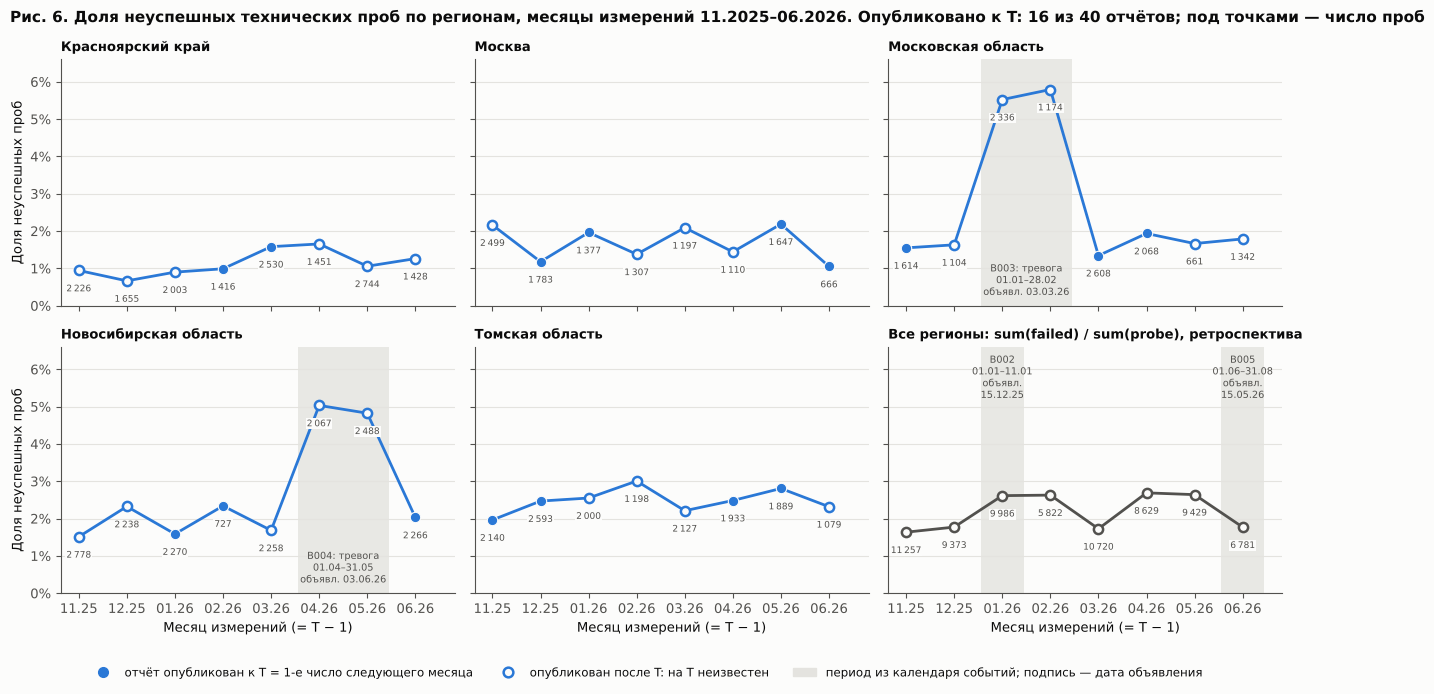

In [30]:
PLOT_MONTHS = pd.DatetimeIndex([T - pd.DateOffset(months=1) for T in EDA_DATES])
REGIONS = sorted(network.region.unique())
month_pos = {m: i for i, m in enumerate(PLOT_MONTHS)}


def shade_period(ax, start: pd.Timestamp, end: pd.Timestamp, label: str, top: bool = False) -> None:
    months = [m for m in PLOT_MONTHS if start <= m + pd.offsets.MonthEnd(0) and m <= end]
    if not months:
        return
    left, right = month_pos[months[0]] - 0.45, month_pos[months[-1]] + 0.45
    ax.axvspan(left, right, color=COLORS["grid"], alpha=0.8, zorder=0, linewidth=0)
    y, va = (0.064, "top") if top else (0.002, "bottom")
    ax.text((left + right) / 2, y, label, ha="center", va=va, fontsize=7, color=COLORS["muted"])


fig6 = network_at_T.assign(failed_probe_rate=network_at_T.failed_probe_count / network_at_T.probe_count)
fig, axes = plt.subplots(2, 3, figsize=(13, 6.8), sharex=True, sharey=True)
for ax, region in zip(axes.flat, REGIONS + ["Все регионы"]):
    if region == "Все регионы":
        part = pooled[pooled.measurement_month.isin(PLOT_MONTHS)].sort_values("measurement_month")
        known = pd.Series(False, index=part.index)
        line_color = COLORS["muted"]
        title = "Все регионы: sum(failed) / sum(probe), ретроспектива"
        for c in context.itertuples():
            if c.scope == "all_regions" and c.event_type == "seasonal_context":
                shade_period(ax, c.event_start, c.event_end,
                             f"{c.context_id}\n{c.event_start:%d.%m}–{c.event_end:%d.%m}\nобъявл.\n{c.announced_at:%d.%m.%y}", top=True)
    else:
        part = fig6[fig6.region == region].sort_values("measurement_month")
        known = part.report_known_at_T
        line_color = COLORS["s1"]
        title = region
        for c in context[(context.scope == "region") & (context.region == region)].itertuples():
            shade_period(ax, c.event_start, c.event_end,
                         f"{c.context_id}: тревога\n{c.event_start:%d.%m}–{c.event_end:%d.%m}\nобъявл. {c.announced_at:%d.%m.%y}")
    x = part.measurement_month.map(month_pos).to_numpy()
    y = part.failed_probe_rate.to_numpy()
    ax.plot(x, y, color=line_color, linewidth=2, zorder=2)
    ax.scatter(x[known.to_numpy()], y[known.to_numpy()], s=56, color=line_color, edgecolor=COLORS["surface"],
               linewidth=0.8, zorder=3)
    ax.scatter(x[~known.to_numpy()], y[~known.to_numpy()], s=44, facecolor=COLORS["surface"],
               edgecolor=line_color, linewidth=1.8, zorder=3)
    for xi, yi, n in zip(x, y, part.probe_count):
        ax.annotate(fmt_int(n), (xi, yi), textcoords="offset points", xytext=(0, -15), ha="center",
                    fontsize=6.5, color=COLORS["muted"], zorder=4,
                    bbox={"boxstyle": "square,pad=0.1", "facecolor": COLORS["surface"], "edgecolor": "none"})
    ax.set_title(title, fontsize=9.5)
    ax.grid(axis="x", visible=False)
ax0 = axes[0, 0]
ax0.set_ylim(0, 0.066)
ax0.yaxis.set_major_formatter(lambda v, _: fmt_pct(v, 0))
for ax in axes[:, 0]:
    ax.set_ylabel("Доля неуспешных проб")
for ax in axes[1, :]:
    ax.set_xticks(range(len(PLOT_MONTHS)), [f"{m:%m.%y}" for m in PLOT_MONTHS])
    ax.set_xlabel("Месяц измерений (= T − 1)")
handles = [plt.Line2D([], [], marker="o", linestyle="", markersize=7, color=COLORS["s1"],
                      label="отчёт опубликован к T = 1-е число следующего месяца"),
           plt.Line2D([], [], marker="o", linestyle="", markersize=7, markerfacecolor=COLORS["surface"],
                      markeredgecolor=COLORS["s1"], markeredgewidth=1.8, label="опубликован после T: на T неизвестен"),
           Patch(color=COLORS["grid"], label="период из календаря событий; подпись — дата объявления")]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=8.5, bbox_to_anchor=(0.5, -0.02))
n_known = int(fig6.report_known_at_T.sum())
fig.suptitle(f"Рис. 6. Доля неуспешных технических проб по регионам, месяцы измерений 11.2025–06.2026. "
             f"Опубликовано к T: {n_known} из {len(fig6)} отчётов; под точками — число проб",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout(rect=(0, 0.04, 1, 1))
save_figure(fig, "fig6_network_failed_probes")

write_csv(pd.concat([
    fig6[["region", "measurement_month", "snapshot_at", "probe_count", "failed_probe_count", "failed_probe_rate",
          "report_available_at", "report_known_at_T"]],
    pooled[pooled.measurement_month.isin(PLOT_MONTHS)]
    .assign(snapshot_at=lambda p: (p.measurement_month + pd.DateOffset(months=1)).map(snapshot_moment),
            report_known_at_T=pd.NA)
    [["region", "measurement_month", "snapshot_at", "probe_count", "failed_probe_count", "failed_probe_rate",
      "report_known_at_T"]],
], ignore_index=True).round({"failed_probe_rate": 6}), TABLES / "fig6_network_failed_probes.csv")

### Сеть и отток: что можно сравнить

Единица сравнения — регион × T, не абонент: региональная доля ошибок не описывает связь конкретного человека. Как предиктор на T допустимы только 16 опубликованных к T значений; ретроспективная колонка (все отчёты) показана отдельно и для выбора признаков не используется.

In [31]:
churn_region_T = churn_by(eda, ["region", "snapshot_at"])
network_vs_churn = churn_region_T.merge(
    fig6[["region", "snapshot_at", "measurement_month", "report_known_at_T", "failed_probe_rate"]]
    .rename(columns={"failed_probe_rate": "failed_rate_retrospective"}),
    on=["region", "snapshot_at"], how="left", validate="1:1")
network_vs_churn["failed_rate_known_at_T"] = network_vs_churn.failed_rate_retrospective.where(
    network_vs_churn.report_known_at_T)
write_csv(network_vs_churn.round({"failed_rate_retrospective": 6, "failed_rate_known_at_T": 6}),
          TABLES / "network_vs_churn_region_T.csv")

known_cells = network_vs_churn.dropna(subset=["failed_rate_known_at_T"])
rho_known = known_cells[["failed_rate_known_at_T", "churn_rate"]].corr(method="spearman").iloc[0, 1]
rho_retro = network_vs_churn[["failed_rate_retrospective", "churn_rate"]].corr(method="spearman").iloc[0, 1]
alerts = network_vs_churn[network_vs_churn.failed_rate_retrospective > 0.04]
print(f"Region x T cells: {len(network_vs_churn)}; with a report known at T: {len(known_cells)}.")
print(f"Spearman, known at T (n={len(known_cells)}): {rho_known:.2f}; retrospective, all cells "
      f"(n={len(network_vs_churn)}): {rho_retro:.2f} — descriptive only.")
print(f"Cells with failed rate > 4% (alert months): {len(alerts)}, known at T: {int(alerts.report_known_at_T.sum())}")
alerts[["region", "snapshot_at", "measurement_month", "failed_rate_retrospective", "report_known_at_T",
        "n_observations", "n_churn", "churn_rate"]]

Region x T cells: 40; with a report known at T: 16.
Spearman, known at T (n=16): -0.24; retrospective, all cells (n=40): -0.17 — descriptive only.
Cells with failed rate > 4% (alert months): 4, known at T: 0


,region,snapshot_at,measurement_month,failed_rate_retrospective,report_known_at_T,n_observations,n_churn,churn_rate
18,Московская область,2026-02-01 00:00:00+03:00,2026-01-01,0.055223,False,395,15,0.037975
19,Московская область,2026-03-01 00:00:00+03:00,2026-02-01,0.057922,False,391,10,0.025575
29,Новосибирская область,2026-05-01 00:00:00+03:00,2026-04-01,0.050314,False,398,15,0.037688
30,Новосибирская область,2026-06-01 00:00:00+03:00,2026-05-01,0.048232,False,394,9,0.022843


*Шаг 5. Новые источники и контекст*

---

## Шаг 6. Результаты гипотез

Результат каждой гипотезы формулируется по одному правилу:

- **поддерживается на исследованном периоде** — 95%-интервал разницы долей (кластерный бутстреп по абонентам) не включает 0;
- **не поддерживается** — интервал включает 0, а сама разница меньше 0,5 п.п.: даже при наличии связи она практически незаметна;
- **данных недостаточно** — интервал включает 0, но разница не меньше 0,5 п.п.

Для H3 сравниваются не две группы, а восемь дат, поэтому правило другое: связь поддерживается, если доля оттока меняется в одну сторону на каждой смене даты.

Числа подставляются из таблиц шагов 4–5. «Поддерживается» означает устойчивую связь на этих данных, а не причину.

In [32]:
NEGLIGIBLE_DIFF = 0.005


def verdict(diff: float, low: float, high: float) -> str:
    if low > 0 or high < 0:
        return "поддерживается на исследованном периоде"
    if abs(diff) < NEGLIGIBLE_DIFF:
        return "не поддерживается"
    return "данных недостаточно"


def pp(x: float) -> str:
    return fmt_num(x * 100, 1) + " п.п."


def interval(row: pd.Series) -> str:
    return f"[{fmt_num(row.cluster_ci_low * 100, 1)}; {fmt_num(row.cluster_ci_high * 100, 1)}] п.п."


ci = intervals.set_index(["factor", "group_a", "group_b"])
debt_ci = ci.loc[("debt_group", ">0", "=0")]
support_ci = ci.loc[("support_any", "≥1", "0")]
tenure_ci = ci.loc[("tenure_group", "<90", "≥365")]
debt_rows = churn_debt.set_index("debt_group")
support_rows = churn_support.set_index("support_group")
tenure_rows = churn_tenure.set_index("tenure_group")
td = churn_tenure_debt.set_index(["debt_group", "tenure_group"]).churn_rate
network_share = churners_vs_stayers[churners_vs_stayers.indicator == "support_network_count"].set_index("churn_target")
steps = churn_T.churn_rate.diff().dropna()
base_change = churn_T.n_observations.iloc[-1] / churn_T.n_observations.iloc[0] - 1
monotone_debt = all(td[(g, a)] > td[(g, b)] for g in [">0", "=0"]
                    for a, b in [("<90", "≥365"), ("90–364", "≥365")])

results = {
    "H1": (
        f"{verdict(debt_ci['diff'], debt_ci.cluster_ci_low, debt_ci.cluster_ci_high)}: "
        f"{fmt_pct(debt_rows.loc['>0', 'churn_rate'])} при долге >0 ({debt_rows.loc['>0', 'n_churn']} / "
        f"{fmt_int(debt_rows.loc['>0', 'n_observations'])} строк, {fmt_int(debt_rows.loc['>0', 'n_customers'])} аб.) "
        f"против {fmt_pct(debt_rows.loc['=0', 'churn_rate'])} при долге 0 ({debt_rows.loc['=0', 'n_churn']} / "
        f"{fmt_int(debt_rows.loc['=0', 'n_observations'])}); разница {pp(debt_ci['diff'])}, интервал {interval(debt_ci)}; "
        f"доля выше у должников в {int((strata.rate_debt > strata.rate_no_debt).sum())} из {len(strata)} срезов "
        f"(месяц, тариф, стаж, регион), отношение долей {fmt_num(strata.rate_ratio.min(), 1)}–"
        f"{fmt_num(strata.rate_ratio.max(), 1)}",
        "Рис. 4; tables/fig4_churn_by_debt_support.csv, tables/debt_within_strata.csv, "
        "tables/rate_difference_intervals.csv",
        "Признаки долга и задержки оплаты по нескольким доступным месяцам; задержка почти дублирует долг "
        "(Спирмен 0,79) — выбрать одно или проверить вместе"),
    "H2": (
        f"{verdict(support_ci['diff'], support_ci.cluster_ci_low, support_ci.cluster_ci_high)}: "
        f"{fmt_pct(support_rows.loc['0', 'churn_rate'])} при 0 обращений, {fmt_pct(support_rows.loc['1', 'churn_rate'])} "
        f"при 1, {fmt_pct(support_rows.loc['≥2', 'churn_rate'])} при ≥2; разница «≥1 против 0» "
        f"{pp(support_ci['diff'])}, интервал {interval(support_ci)}; обращения по теме network у ушедших "
        f"{fmt_pct(network_share.loc[1, 'share_positive'])} строк, у оставшихся {fmt_pct(network_share.loc[0, 'share_positive'])}",
        "Рис. 4; tables/fig4_churn_by_debt_support.csv, tables/churners_vs_stayers.csv",
        "Проверить окно в 2–3 месяца и тему billing; история до 01.11.2025 идёт из другой системы поддержки (B001)"),
    "H3": (
        f"{'поддерживается на исследованном периоде' if (steps > 0).all() or (steps < 0).all() else 'данных недостаточно'}: "
        f"доля оттока растёт на {int((steps > 0).sum())} из {len(steps)} смен даты, "
        f"{fmt_pct(churn_T.churn_rate.iloc[0], 2)} ({churn_T.n_churn.iloc[0]} / {fmt_int(churn_T.n_observations.iloc[0])}) "
        f"на 01.12.2025 → {fmt_pct(churn_T.churn_rate.iloc[-1], 2)} ({churn_T.n_churn.iloc[-1]} / "
        f"{fmt_int(churn_T.n_observations.iloc[-1])}) на 01.07.2026; активная база меняется на {fmt_pct(base_change)}",
        "Рис. 3; tables/fig3_churn_by_T.csv",
        "Разбиение только по времени; дата T или номер месяца как признак уровня; уровень оттока на "
        "отложенных датах заранее не подбирать"),
    "H4": (
        f"{verdict(tenure_ci['diff'], tenure_ci.cluster_ci_low, tenure_ci.cluster_ci_high)}: "
        f"{fmt_pct(tenure_rows.loc['<90', 'churn_rate'])} при стаже <90 дней ({tenure_rows.loc['<90', 'n_churn']} / "
        f"{fmt_int(tenure_rows.loc['<90', 'n_observations'])}), {fmt_pct(tenure_rows.loc['90–364', 'churn_rate'])} при "
        f"90–364, {fmt_pct(tenure_rows.loc['≥365', 'churn_rate'])} при ≥365; разница «<90 против ≥365» "
        f"{pp(tenure_ci['diff'])}, интервал {interval(tenure_ci)}; в обеих группах долга стаж <365 дней "
        f"{'даёт более высокую долю, чем ≥365' if monotone_debt else 'не всегда даёт более высокую долю, чем ≥365'}",
        "Рис. 5; tables/fig5_churn_by_tenure.csv, tables/rate_difference_intervals.csv",
        "Стаж в днях как непрерывный признак и число доступных месяцев истории; группа <90 дней мала — "
        "проверить на большем периоде"),
}
for hid, (result, evidence, action) in results.items():
    HYPOTHESES.loc[HYPOTHESES.hypothesis_id == hid, ["result", "evidence", "next_action"]] = [result, evidence, action]
write_csv(HYPOTHESES, Path("analysis_plan.csv"))
for hid, (result, _, _) in results.items():
    print(f"{hid}: {result}\n")

H1: поддерживается на исследованном периоде: 7,5% при долге >0 (276 / 3 661 строк, 1 784 аб.) против 1,4% при долге 0 (164 / 12 035); разница 6,2 п.п., интервал [5,3; 7,1] п.п.; доля выше у должников в 19 из 19 срезов (месяц, тариф, стаж, регион), отношение долей 3,9–7,5

H2: не поддерживается: 2,7% при 0 обращений, 3,0% при 1, 3,0% при ≥2; разница «≥1 против 0» 0,3 п.п., интервал [-0,2; 0,9] п.п.; обращения по теме network у ушедших 15,9% строк, у оставшихся 16,1%

H3: поддерживается на исследованном периоде: доля оттока растёт на 7 из 7 смен даты, 2,44% (48 / 1 969) на 01.12.2025 → 3,19% (62 / 1 941) на 01.07.2026; активная база меняется на -1,4%

H4: данных недостаточно: 3,6% при стаже <90 дней (40 / 1 097), 3,4% при 90–364, 2,7% при ≥365; разница «<90 против ≥365» 1,0 п.п., интервал [-0,1; 2,1] п.п.; в обеих группах долга стаж <365 дней даёт более высокую долю, чем ≥365



*Шаг 6. Результаты гипотез*

---

## Итог проверок

Последние две проверки — воспроизводимость:

1. `eda_sample` строится заново из входных файлов и сравнивается с уже построенной таблицей.
2. Контрольные суммы всех файлов, которые пишет ноутбук, сравниваются с предыдущим запуском (`output/checksums.csv`). При первом запуске сравнивать не с чем. Если код или данные менялись намеренно, проверка один раз остановит ноутбук со списком изменившихся файлов; следующий запуск сравнит уже с новой версией.

In [33]:
import hashlib

rebuilt = pd.concat([build_snapshot(T, build_lifecycle(events)) for T in EDA_DATES], ignore_index=True)
record_check("rebuilding eda_sample from the inputs gives the same table", rebuilt.equals(eda_sample),
             f"{len(rebuilt)} rows, {rebuilt.shape[1]} columns")

generated = sorted(p for p in OUTPUT.rglob("*") if p.is_file() and p.name not in {"checks.csv", "checksums.csv"})
generated += [DOCS / "eda_sample_dictionary.csv", Path("analysis_plan.csv")]
current = pd.DataFrame({"file": [p.as_posix() for p in generated],
                        "sha256": [hashlib.sha256(p.read_bytes()).hexdigest() for p in generated]})
checksums_path = OUTPUT / "checksums.csv"
if checksums_path.exists():
    previous = read_csv(checksums_path)
    merged = previous.merge(current, on="file", how="outer", suffixes=("_previous", "_current"))
    changed = merged.loc[merged.sha256_previous != merged.sha256_current, "file"].tolist()
    passed, detail = not changed, f"{len(current)} files compared with the previous run; changed: {changed or 'none'}"
else:
    passed, detail = True, f"{len(current)} files; first run, nothing to compare yet"
write_csv(current, checksums_path)
record_check("rerun reproduces every generated file byte for byte", passed, detail)

checks = pd.DataFrame(CHECKS)
write_csv(checks, OUTPUT / "checks.csv")
print(f"{int(checks.passed.sum())} of {len(checks)} checks passed; written to {OUTPUT / 'checks.csv'}")
checks

19 of 19 checks passed; written to output/checks.csv


,check,passed,detail
0,"key (customer_id, snapshot_at) is unique",True,duplicates: 0
1,active base matches an independent recount fro...,True,8 dates; rows 15696 vs 15696; churn 440 vs 440
2,base size and churn per T match the project ch...,True,total 15696 rows / 440 churn; charter 15696 / 440
3,activation date in events equals subscribers_c...,True,all customers
4,billing_available_at <= snapshot_at and source...,True,15696 rows with a billing row
5,every active customer has a billing row for T-1,True,"rows without T-1 billing (kept, not dropped): 0"
6,termination date is not a column of eda_sample,True,columns: none
7,boundary events on T and on the horizon end fo...,True,activation on T excluded; termination on T = c...
8,horizon ending after 2026-10-01 gives an unkno...,True,"T=2026-10-01: 2 rows, all labels empty"
9,debt identity closing = opening + charged - pa...,True,rows violating by more than 0.01 rub: 0


*Итог проверок*

---